# F02.05 · Auditoría de atajos: ¿puede el modelo acertar sin mirar el EEG preictal?

> 🧭 **En 30 segundos**
> - **Para qué:** antes de entrenar, comprobar si en los datos hay **pistas que no son el EEG preictal** (canales a 0, equipo, minuto del fichero, tipo de fichero...) y que separen ⏳ preictal de 💤 interictal. Si las hay, una red puede "aprobar" mirando esas pistas: es un **atajo**.
> - **Entra:** `conjuntos/<modelo>.csv` (**F02.04**) + `senales.csv` (**F02.02**) + `edfs.csv` (Fase 1) → **Sale:** el **semáforo** de cada pista, la nota de un modelo que **solo ve metadatos** (el "techo del atajo": cuánto podría inflar la nota una pista) y **dos conjuntos de control** para la Fase 3.
> - **Idea clave:** si un modelo **sin ver la señal** ya separa las clases, hay que comprobar en la Fase 3 que la red **mantiene su nota en los conjuntos de control**, donde esas pistas ya no sirven.

> 📍 **Dónde estamos: Fase 2 · notebook 5 de 5 (F02.05).** **F02.04** dejó los conjuntos listos para entrenar. Este notebook **no cambia nada de ellos**: los audita. Es la última comprobación antes de la Fase 3.

> 🏷️ **Cómo se nombran los notebooks.** `F02.04` = Fase 2, notebook 04 (`fase_02/04_particiones_y_balanceo.ipynb`). Este es el **F02.05**.

> 🔄 **Es dinámico.** Lee la configuración de **F02.03** y **F02.04** y **todas las cifras, semáforos y conclusiones salen de los datos** al ejecutarlo. Si cambian los umbrales, las ventanas o los conjuntos, se vuelve a ejecutar y concluye solo.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| **Fase 2** | **Preprocesado y ventanas** | 👉 **en curso** (la fase de este notebook) |
| Fase 3 | Modelo de predicción (⏳ preictal frente a 💤 interictal) | pendiente |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## Qué hace este notebook

1. Calcula, para cada ventana, **7 variables de atajo**: pistas que no son EEG preictal (sección 3).
2. Plantea **5 hipótesis**, cada una con **qué buscamos, por qué y qué esperamos** encontrar (sección 4).
3. Las comprueba **una a una**, con tablas, figuras y un **veredicto automático** (secciones 5 a 8).
4. Junta todo en un **semáforo** de las variables (sección 9).
5. Entrena modelos que **solo ven metadatos** y calcula el **techo del atajo**: lo que se acierta sin mirar el EEG (sección 10).
6. Prepara los **remedios**: un conjunto de **control emparejado por posición** y otro de **control de tipo de fichero** con 💤 de la misma sesión (secciones 11 y 12).
7. Deja las **medidas para la Fase 3**, también decididas por los datos (sección 13).

**Requisito**: haber ejecutado **F02.04**.

## Cómo leer este notebook

Cada sección de hipótesis sigue el mismo guion: 🔎 **Qué buscamos** · 🤔 **Por qué** · 🎯 **Qué esperamos** → tabla y figura → 🧾 **Veredicto** calculado con los datos. Los conceptos difíciles llevan una **imagen explicativa** (esquemas sintéticos, no datos), con un 👀 **Qué enseña** debajo. Las figuras con datos reales llevan un 👀 **Cómo leer la figura**.

## Los notebooks de la Fase 2

| | Notebook | Qué hace | Entrada → salida | Estado |
|---|---|---|---|---|
| | **F02.01** · `01_seleccion_crisis` | Elige qué señal se usa: tramos 💤 interictal, ⏳ preictal y ⚡ ictal. | Inventario → `tramos.csv` | ✅ |
| | **F02.02** · `02_preprocesado` | Deja la señal en un formato común (TCP 22 canales, 256 Hz, filtrada, float16). | EDF → `senales/*.npy` + `senales.csv` | ✅ |
| | **F02.03** · `03_ventanas` | Corta en ventanas, decide a qué modelo pertenece cada una y marca las de mala calidad. | `senales.csv` → `ventanas.csv` | ✅ |
| | **F02.04** · `04_particiones_y_balanceo` | Limita las 💤 interictales por paciente, arma un conjunto por modelo y equilibra el entrenamiento. | `ventanas.csv` → `conjuntos/*.csv` | ✅ |
| 👉 | **F02.05** · `05_auditoria_atajos` | **Busca pistas que no son EEG preictal, mide cuánto separan y prepara el control.** | `conjuntos/` + `senales.csv` + `edfs.csv` → semáforo + control | **este notebook** |

![El recorrido del notebook 05](img/mapa_notebook_05.png)

👀 **Qué enseña.** Las secciones en orden. Arriba, las que **miden** (pistas, comprobaciones, hipótesis, semáforo); abajo, en rojo, las que **preparan lo que se lleva la Fase 3** (techo del atajo, dos controles y medidas). El notebook no modifica nada de **F02.04**: solo audita.

## Conceptos clave

**Atajo (shortcut learning).** Una red aprende **lo más fácil** que separe las clases, sea o no lo que buscamos (Geirhos et al., 2020). Ejemplos reales en medicina:

- Modelos de **radiografías** que detectaban neumonía reconociendo **el hospital** por las marcas de la placa, no por el pulmón (Zech et al., 2018).
- Modelos de **lesiones de piel** que daban más melanoma cuando había **marcas de rotulador** del dermatólogo (Winkler et al., 2019).

En nuestro caso, si las ⏳ preictales salen más a menudo de un equipo concreto, del **principio** de la grabación o con **dos canales a 0**, la red puede acertar mirando **eso**. En 🟢 eval sacaría buena nota, pero no serviría con otros pacientes ni en la demo.

**Vocabulario del notebook**

- **Variable de atajo**: una pista convertida en un número por ventana (p. ej. el minuto del fichero en el que empieza).
- **AUROC**: probabilidad de que una ⏳ preictal al azar tenga un valor **mayor** que una 💤 interictal al azar. **0,5 = no separa**; 1 o 0 = separa del todo (0 es "al revés").
- **Fuerza** = max(AUROC, 1 − AUROC): cuánto separa, sin importar el sentido. Va de **0,5 (nada)** a **1 (todo)**. Se calcula sobre la variable **codificada por franjas** (`codificar_por_franjas`): cada franja vale su proporción de ⏳ en train. Así se ven también pistas con "forma" (p. ej. *el primer minuto es casi solo 💤 y los minutos 2-5 casi solo ⏳*), que la AUROC de la variable tal cual no ve.
- **Semáforo** (`atajos.py`): 🟢 fuerza < 0,55 (no separa) · 🟡 0,55-0,65 (separa un poco) · 🔴 > 0,65 (separa lo bastante como para que una red la use). No son umbrales oficiales: son cortes habituales para leer una AUROC.
- **Qué fuerza decide el semáforo**: la de **🔵 train, dentro del paciente**, porque es lo único que la red **puede aprender** (entrena con train equilibrado paciente a paciente). Las fuerzas de dev y eval se enseñan como información: una diferencia **entre** pacientes de dev no la aprende la red, aunque mueva un poco la nota.
- **Dentro del paciente**: el entrenamiento está equilibrado **paciente a paciente** (**F02.04**). Por eso una pista que solo cambia **entre** pacientes no le sirve a la red: cada paciente aporta mitad y mitad. La peligrosa es la que cambia **dentro** del mismo paciente.
- **Techo del atajo**: la AUROC de un modelo que **solo ve metadatos**. **No es una nota que la red tenga que superar** (la red no lee el minuto del fichero, solo podría notarlo en el EEG): es lo **máximo que podría inflar la nota** esa pista. La prueba de verdad es la nota de la red en los **conjuntos de control**.

La figura de abajo resume la idea.

![Qué es un atajo](img/que_es_un_atajo.png)

*Imagen diseñada aparte (fuente editable: `img/que_es_un_atajo.svg`), sin código en el notebook.*

👀 **Cómo leer la figura.** Arriba, en negro, lo que queremos que aprenda la red: los cambios del EEG antes de una crisis. Abajo, en rojo discontinuo, el atajo: pistas que **viajan con la ventana** pero no son EEG preictal. Si esas pistas separan las clases, la red puede llegar a la salida por abajo. Las dos en rojo (minuto del fichero y tipo de fichero) son las que más separan en TUSZ. La franja de abajo resume cómo lo vigila este notebook: medir cada pista (§9), calcular el techo del atajo (§10) y preparar los controles para la Fase 3 (§11-12).

![Cómo se lee la fuerza de una pista](img/auroc_y_fuerza.png)

👀 **Qué enseña.** Una **pista** es cualquier dato que acompaña a la ventana y que no es el cambio del EEG antes de la crisis (aquí, el minuto del fichero en que empieza). Si ⏳ y 💤 tienen los mismos valores de la pista, la AUROC es 0,5 y no separa; si el ⏳ tiene valores más altos **o más bajos**, separa igual de bien. Por eso se usa la **fuerza** = max(AUROC, 1 − AUROC), y abajo se ve cómo se convierte en semáforo.

![Fuerza por franjas](img/fuerza_por_franjas.png)

👀 **Qué enseña.** Una **franja** es un trozo del rango de la pista con el mismo número de ventanas de train (por ejemplo, minuto 0-1, 1-2… 19-30). Una pista de "cuanto más, más preictal" es la que siempre va en la misma dirección; el minuto del fichero no lo es, porque el % de ⏳ sube en los minutos 1-4 y luego baja, y la AUROC normal lo ve casi como azar. Dando a cada ventana el % de ⏳ de su franja, la fuerza sí recoge esa forma.

![Por qué importa dentro del paciente](img/dentro_del_paciente.png)

👀 **Qué enseña.** En el entrenamiento cada paciente entra **mitad y mitad**: tantas ventanas ⏳ como 💤 suyas. A la izquierda, los **Hz del equipo**: cambian de un paciente a otro, pero dentro de cada uno son iguales en ⏳ y en 💤, así que a la red no le sirven (fuerza dentro del paciente ≈ 0,5). A la derecha, el **minuto del fichero**: dentro de cada paciente sus ⏳ empiezan antes que sus 💤, así que la red sí lo podría aprender. Por eso el semáforo se decide con la fuerza dentro del paciente.

In [22]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_05_ATAJOS
disponibles = comprobar_requisitos(REQUISITOS_05_ATAJOS)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scikit-learn,✅,1.9.1,AUROC y modelos sencillos (regresión logística y árboles) con solo metadatos


Todo lo necesario está instalado.


## 1. Importación de librerías

Las reglas están en `tfm_comun/prediccion/`: `atajos.py` (variables de atajo, fuerza, semáforo y emparejado por posición) y `metricas.py` (AUROC con intervalo de confianza por paciente). El notebook las aplica y explica el resultado.

In [23]:
# Recarga automática: si cambia un módulo de tfm_comun, se vuelve a cargar solo (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2

# Vuelve a leer tfm_comun del disco cada vez que se ejecuta esta celda (por si ha cambiado), sin reiniciar el kernel
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from matplotlib.patches import Patch
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_01, RUTA_OUTPUTS_FASE_02
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.dataset.particiones import SPLITS
from tfm_comun.prediccion.balanceo import SEMILLA
from tfm_comun.prediccion.atajos import (VARIABLES_ATAJO, FUERZA_DEBIL, FUERZA_FUERTE, metadatos_de_ventanas,
                                         codificar_por_tasa, codificar_por_franjas, fuerza_auroc, fuerza_dentro_del_paciente,
                                         semaforo, emparejar_por_posicion, marcar_sesiones, RESOLUCION_POSICION_S)
from tfm_comun.prediccion.metricas import auroc_con_intervalo
from tfm_comun.visual.iconos import con_icono, tabla_con_iconos, ICONO_CLASE
from tfm_comun.visual.colores import COLORES_SPLIT, COLORES_PERIODO, COLOR_DESTACADO
from tfm_comun.visual.numeros import numero_legible
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, sklearn)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
sklearn     1.9.1


## 2. Configuración

| Parámetro | Valor | Qué controla |
|---|---|---|
| `CONJUNTO` | `'general'` | Qué conjunto de **F02.04** se audita. Se puede cambiar por `umbral_5min`, `grupo_focal`... o lanzar con papermill para todos |
| `N_BOOTSTRAP` | 500 | Repeticiones del bootstrap por paciente para los intervalos de confianza (más = más estable y más lento) |
| `ANCHO_FRANJA_MIN` | 1 | Anchura (min) de las franjas del fichero para emparejar por posición (sección 11) |
| `RATIO_CONTROL` | 1 | 💤 interictales por cada ⏳ preictal en cada franja del conjunto de control |

Lo demás **no se fija aquí**: la ventana, el umbral principal y la frecuencia se leen de `03_ventanas/configuracion.json`; el máximo por paciente y el ratio del equilibrado, de `04_particiones_y_balanceo/configuracion.json`. Así, si cambian en **F02.03** o **F02.04**, este notebook se entera solo.

La celda de parámetros tiene la etiqueta `parameters`, por si se lanza con papermill.

In [24]:
CONJUNTO = 'general'
N_BOOTSTRAP = 500
ANCHO_FRANJA_MIN = 1
RATIO_CONTROL = 1.0

In [25]:
# Rutas
RUTA_VENTANAS = RUTA_OUTPUTS_FASE_02 / '03_ventanas'
RUTA_CONJUNTOS_04 = RUTA_OUTPUTS_FASE_02 / '04_particiones_y_balanceo'
RUTA_SENALES_CSV = RUTA_OUTPUTS_FASE_02 / '02_preprocesado' / 'senales.csv'
RUTA_EDFS = RUTA_OUTPUTS_FASE_01 / '01_inventario' / 'edfs.csv'
RUTA_TRAMOS = RUTA_OUTPUTS_FASE_02 / '01_seleccion' / 'tramos.csv'
RUTA_RESULTADOS = RUTA_OUTPUTS_FASE_02 / '05_auditoria_atajos'
RUTA_FIGURAS = RUTA_RESULTADOS / 'figuras'
RUTA_CONTROL = RUTA_RESULTADOS / 'conjuntos_control'
for ruta in [RUTA_FIGURAS, RUTA_CONTROL]:
    ruta.mkdir(parents=True, exist_ok=True)

for ruta, notebook in [(RUTA_CONJUNTOS_04 / 'conjuntos' / f'{CONJUNTO}.csv', 'fase_02/04_particiones_y_balanceo'),
                       (RUTA_CONJUNTOS_04 / 'configuracion.json', 'fase_02/04_particiones_y_balanceo'),
                       (RUTA_VENTANAS / 'configuracion.json', 'fase_02/03_ventanas'),
                       (RUTA_SENALES_CSV, 'fase_02/02_preprocesado'), (RUTA_EDFS, 'fase_01/01_inventario_tusz'),
                       (RUTA_TRAMOS, 'fase_02/01_seleccion_crisis')]:
    assert ruta.exists(), f'No encuentro {ruta}. Ejecuta antes {notebook}.ipynb.'

# Lo que viene de los notebooks anteriores (no se escribe a mano: si cambia allí, cambia aquí)
config_03 = json.loads((RUTA_VENTANAS / 'configuracion.json').read_text(encoding='utf-8'))
config_04 = json.loads((RUTA_CONJUNTOS_04 / 'configuracion.json').read_text(encoding='utf-8'))
VENTANA_S = config_03['ventana_s']
FS = config_03['muestras_por_ventana'] / config_03['ventana_s']          # frecuencia de la señal guardada
modo_prueba = bool(config_03.get('modo_prueba')) or bool(config_04.get('modo_prueba'))

display(Markdown(
    f'**Leído de los notebooks anteriores**  \n'
    f'- `03`: ventanas de **{VENTANA_S} s** a **{numero_legible(FS)} Hz**, umbral principal **{config_03["umbral_principal_min"]} min**, '
    f'solape {", ".join(f"{ICONO_CLASE[c]} {c} {v:.0%}" for c, v in config_03["solape_por_clase"].items())}  \n'
    f'- `04`: máximo de **{numero_legible(config_04["max_horas_interictal_por_paciente"])} h** de 💤 interictal por paciente, '
    f'**{numero_legible(config_04["ratio_entrenamiento"])}** 💤 interictal por cada ⏳ preictal en el entrenamiento  \n'
    + ('- 🔴 **MODO PRUEBA** en 03 o 04: las cifras de este notebook no son representativas.' if modo_prueba else '')))

config = {
    'conjunto': CONJUNTO, 'n_bootstrap': N_BOOTSTRAP, 'ancho_franja_min': ANCHO_FRANJA_MIN, 'ratio_control': RATIO_CONTROL,
    'fuerza_debil': FUERZA_DEBIL, 'fuerza_fuerte': FUERZA_FUERTE, 'semilla': SEMILLA,
    'ventana_s': VENTANA_S, 'fs': FS, 'umbral_principal_min': config_03['umbral_principal_min'], 'modo_prueba': modo_prueba,
    'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
with open(RUTA_RESULTADOS / 'configuracion.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=4, ensure_ascii=False)
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json',
                'los parámetros de la auditoría (conjunto, bootstrap, franjas, cortes del semáforo), lo leído de 03, las versiones y la fecha')

**Leído de los notebooks anteriores**  
- `03`: ventanas de **4 s** a **256 Hz**, umbral principal **4 min**, solape 💤 interictal 0%, ⏳ preictal 50%, ⚡ ictal 50%  
- `04`: máximo de **2 h** de 💤 interictal por paciente, **1** 💤 interictal por cada ⏳ preictal en el entrenamiento  


💾 **Guardado `configuracion.json`** · 491 B · 13 claves  
*Qué guarda:* los parámetros de la auditoría (conjunto, bootstrap, franjas, cortes del semáforo), lo leído de 03, las versiones y la fecha. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
n_bootstrap,500
ancho_franja_min,1
ratio_control,1.0
fuerza_debil,0.55
fuerza_fuerte,0.65
semilla,42
ventana_s,4
fs,256.0


## 3. Las variables de atajo de cada ventana

Para cada ventana del conjunto se buscan su **tramo** (`senales.csv`) y su **fichero** (`edfs.csv`), y se calculan 7 variables (`metadatos_de_ventanas`). **No se lee la señal**: todo sale de tablas, así que tarda segundos.

Se miran tres "vistas", las mismas que verá la Fase 3:

- 🔵 **train equilibrado**: solo las ventanas con `entrenamiento_equilibrado = True`. Es **lo que ve la red al aprender**, así que es donde un atajo hace daño.
- 🟡 **dev** y 🟢 **eval**: todas sus ventanas, con su desbalance real.

In [26]:
conjunto = pd.read_csv(RUTA_CONJUNTOS_04 / 'conjuntos' / f'{CONJUNTO}.csv', low_memory=False)
senales = pd.read_csv(RUTA_SENALES_CSV)
edfs = pd.read_csv(RUTA_EDFS)
assert {'interictal', 'preictal'} <= set(conjunto.clase), f'El conjunto {CONJUNTO} no tiene las dos clases: esta auditoría es para predicción.'

ventanas = marcar_sesiones(metadatos_de_ventanas(conjunto, senales, edfs, fs=FS), edfs)
VARIABLES = list(VARIABLES_ATAJO)

def vista(split):
    """Ventanas que se miran en cada partición: en train, solo el entrenamiento equilibrado (lo que ve la red)."""
    v = ventanas[ventanas.split == split]
    return v[v.entrenamiento_equilibrado] if split == 'train' else v

vistas = {s: vista(s) for s in SPLITS if (ventanas.split == s).any()}
tabla_vistas = pd.DataFrame({s: {'pacientes': v.patient.nunique(), '⏳ preictal': int((v.clase == 'preictal').sum()),
                                 '💤 interictal': int((v.clase == 'interictal').sum())} for s, v in vistas.items()}).T
tabla_vistas.index.name = 'vista'
display(con_separadores(tabla_con_iconos(tabla_vistas)))

descripcion = pd.DataFrame({'qué es': {k: v[0] for k, v in VARIABLES_ATAJO.items()},
                            'cómo podría colarse en el modelo': {k: v[1] for k, v in VARIABLES_ATAJO.items()},
                            '¿la red la ve en la ventana?': {k: '👁️ sí, directamente' if v[3] else '🕳️ no, solo si deja huella en el EEG'
                                                             for k, v in VARIABLES_ATAJO.items()}})
descripcion.index.name = 'variable'
display(con_separadores(descripcion).set_properties(**{'text-align': 'left'}))

# Ejemplo: 3 ventanas de cada clase, de PACIENTES DISTINTOS. Las ventanas seguidas de un mismo tramo comparten casi todas
# las pistas (son del tramo o del fichero, y el minuto va de 30 en 30 s), así que con las 3 primeras saldrían 3 filas iguales.
ejemplo = (ventanas.sample(frac=1, random_state=SEMILLA).drop_duplicates(['clase', 'patient'])
           .groupby('clase', group_keys=False).head(3).sort_values(['clase', 'split'])
           [['split', 'patient', 'file', 'clase', *VARIABLES]].set_index('clase'))
display(con_separadores(tabla_con_iconos(ejemplo, ['split']), decimales=5))

,pacientes,⏳ preictal,💤 interictal
vista,,,
🔵 train,84,18.417,18.417
🟡 dev,36,11.190,47.281
🟢 eval,30,8.375,40.211


,qué es,cómo podría colarse en el modelo,¿la red la ve en la ventana?
variable,,,
canales_a_cero,Canales TCP a 0 porque al EDF le faltan A1/A2 (montaje 03_tcp_ar_a),"La red VE dos filas planas en la ventana: si salen más en una clase, es una pista gratis","👁️ sí, directamente"
montaje,"Montaje original del EDF (01_tcp_ar, 02_tcp_le, 03_tcp_ar_a)","Cada referencia deja una ""huella"" algo distinta aunque se pase todo a TCP","👁️ sí, directamente"
fs_original_hz,"Frecuencia de muestreo original del equipo (250, 256, 400, 512, 1000 Hz)","Equipo distinto = filtro antialiasing y ruido distintos, aunque se remuestree a 256 Hz","👁️ sí, directamente"
nivel_senal_uv,Desviación típica mediana de los canales del tramo (µV),"Amplitud ""de fondo"" del registro; la normalización por ventana borra casi toda","👁️ sí, directamente"
minuto_en_fichero,Minuto del fichero EDF en el que empieza la ventana,"En TUSZ las crisis suelen estar al principio de su fichero, así que el ⏳ preictal también; si el EEG de esa parte del fichero es distinto, la red podría notarlo","🕳️ no, solo si deja huella en el EEG"
duracion_fichero_min,Duración total del fichero EDF (min),Ficheros largos y cortos se graban en situaciones distintas (rutina frente a UCI),"🕳️ no, solo si deja huella en el EEG"
fichero_con_crisis,"1 si la ventana sale de un fichero que tiene alguna crisis, 0 si no","Un día con crisis puede ser distinto (sueño, medicación, UCI) aunque la ventana esté lejos de la crisis","🕳️ no, solo si deja huella en el EEG"


,split,patient,file,canales_a_cero,montaje,fs_original_hz,nivel_senal_uv,minuto_en_fichero,duracion_fichero_min,fichero_con_crisis
clase,,,,,,,,,,
💤 interictal,🟡 dev,aaaaampk,aaaaampk_s003_t006,0,01_tcp_ar,256,"6,04221","1,00000","5,00000",0
💤 interictal,🔵 train,aaaaaqtx,aaaaaqtx_s031_t003,0,01_tcp_ar,256,"8,65492","10,00000","16,33333",0
💤 interictal,🔵 train,aaaaaovk,aaaaaovk_s002_t000,0,01_tcp_ar,250,"6,52744","9,00000","22,56667",0
⏳ preictal,🟡 dev,aaaaaoek,aaaaaoek_s029_t002,0,01_tcp_ar,256,"9,53364","2,50000","12,30000",1
⏳ preictal,🟡 dev,aaaaarsp,aaaaarsp_s002_t023,2,03_tcp_ar_a,256,"12,02922","5,00000","30,00000",1
⏳ preictal,🔵 train,aaaaardk,aaaaardk_s002_t018,2,03_tcp_ar_a,256,"6,48522","1,50000","10,05000",1


👀 **Cómo leer las tablas.** La primera: cuántas ventanas tiene cada vista. La segunda: qué es cada variable, cómo podría colarse y si la red la **ve directamente** (👁️) o solo si deja huella en el EEG (🕳️). La tercera: tres ventanas de cada clase con sus 7 variables, cada una de un **paciente distinto** (sorteadas con la semilla del TFM). Se cogen de pacientes distintos porque las ventanas de un mismo tramo comparten casi todas las pistas: casi todas son del tramo o del fichero, y el minuto va de 30 en 30 s.

> 💡 Que una variable sea 🕳️ no la hace inofensiva: el **minuto del fichero** no está escrito en la ventana, pero si el EEG de esa parte del fichero es distinto, la red **sí** lo puede notar.

> 🔍 **Por qué el minuto va de 30 en 30 s** (`RESOLUCION_POSICION_S`). Con el segundo exacto había una **fuga**: las 💤 se cortan desde el principio del tramo y empiezan en segundos múltiplos de 4 (0, 4, 8...), y las ⏳ se cortan desde la crisis y empiezan en segundos con decimales. Un modelo separaba las clases casi perfecto solo con eso, una pista que la red no ve en el EEG. La sección 3b lo enseña.

## 3b. Comprobaciones previas: tres trampas que ya se conocen

Antes de las hipótesis se comprueban tres problemas que encontró la revisión de este notebook. Las dos primeras se corrigen en **F02.03** y **F02.04**; aquí se **verifica** que la corrección está aplicada. La tercera explica por qué la posición se mide de 30 en 30 s.

| | Qué se comprueba | Por qué importa | Qué debe salir |
|---|---|---|---|
| **1** | Ventanas que empiezan en los primeros segundos del fichero | Ahí el filtro de **F02.02** aún arranca. Solo las tenía 💤 interictal (los ficheros sin crisis se cortan desde el segundo 0): **una pista que la red ve** | 0 en las dos clases (**F02.03** las descarta con `descarte_inicio_fichero_s`) |
| **2** | Pacientes de 🔵 train equilibrado que no están mitad y mitad | Si un paciente aporta más ⏳ que 💤, sus rasgos fijos (equipo, canales a 0) se vuelven pista | 0 (**F02.04** con `equilibrado_exacto`) |
| **3** | Fuga de la rejilla de corte | Las 💤 empiezan en segundos múltiplos de 4 y las ⏳ no: con el segundo exacto, un modelo de metadatos "acierta" sin que la red pueda verlo | Muy alta con el segundo exacto; por eso se usa el minuto a 30 s |

![Las tres trampas de la sección 3b](img/tres_trampas.png)

👀 **Qué enseña.** Las tres trampas que encontró la revisión, cómo se corrigen y qué comprueba la tabla de abajo: (1) ventanas en el arranque del filtro, (2) pacientes que no están mitad y mitad, (3) la rejilla de corte que obliga a medir la posición de 30 en 30 s.

![Trampa 2: pacientes que no están mitad y mitad](img/trampa_equilibrado.png)

👀 **Qué enseña.** Si un paciente aporta más ⏳ que 💤 (o solo ⏳), sus rasgos fijos, como la huella de su equipo en la señal, quedan asociados a ⏳ en el entrenamiento: la red acertaría reconociendo al paciente, y eso no sirve con pacientes nuevos. **F02.04** lo corrige dejando a cada paciente exactamente mitad y mitad y quitando a los que no tienen ninguna 💤; la tabla de abajo comprueba que se ha hecho.

![Trampa 3: la rejilla de corte](img/trampa_rejilla.png)

👀 **Qué enseña.** Las 💤 se cortan desde el inicio del tramo cada 4 s y las ⏳ hacia atrás desde la crisis cada 2 s, así que el segundo exacto de inicio delata la clase (cuadrícula de 4 s frente a decimales). La red no ve ese número, pero el modelo de metadatos de la sección 10 sí, y su techo salía inflado. Por eso la posición se mide en franjas de 30 s (`RESOLUCION_POSICION_S`).

In [27]:
DESCARTE_INICIO_S = config_03.get('descarte_inicio_fichero_s')
EQUILIBRADO_EXACTO = config_04.get('equilibrado_exacto')
umbral_inicio = DESCARTE_INICIO_S if DESCARTE_INICIO_S is not None else 10
filas_comprobacion = {}
for s, v in vistas.items():
    en_inicio = v.segundo_en_fichero < umbral_inicio
    por_paciente = v.groupby('patient').etiqueta.mean() if s == 'train' else None
    rejilla = fuerza_auroc(v.etiqueta, np.isclose(v.segundo_en_fichero % VENTANA_S, 0, atol=1e-3).astype(float))[1]
    filas_comprobacion[s] = {
        f'💤 en los primeros {umbral_inicio} s (%)': 100 * en_inicio[v.clase == 'interictal'].mean(),
        f'⏳ en los primeros {umbral_inicio} s (%)': 100 * en_inicio[v.clase == 'preictal'].mean(),
        'pacientes no mitad y mitad': int((np.abs(por_paciente - 0.5) > 1e-9).sum()) if por_paciente is not None else np.nan,
        'fuerza de la rejilla (segundo exacto)': rejilla,
    }
tabla_comprobacion = pd.DataFrame(filas_comprobacion).T
tabla_comprobacion.index.name = 'vista'
display(con_separadores(tabla_con_iconos(tabla_comprobacion), decimales=2))

inicio_ok = tabla_comprobacion.iloc[:, :2].to_numpy().max() == 0
equilibrio_ok = tabla_comprobacion.loc['train', 'pacientes no mitad y mitad'] == 0
rejilla_max = tabla_comprobacion['fuerza de la rejilla (segundo exacto)'].max()
display(Markdown('#### 🧾 Comprobaciones previas (calculadas con los datos)\n' + '\n'.join([
    ('- ✅ **1. Inicio del fichero**: ninguna ventana empieza en los primeros segundos.' if inicio_ok else
     f'- 🔴 **1. Inicio del fichero**: hay ventanas en los primeros {umbral_inicio} s'
     + (' y `03` no tiene la corrección: vuelve a ejecutar `03_ventanas` (con `DESCARTE_INICIO_FICHERO_S`) y `04`.' if DESCARTE_INICIO_S is None else '.')),
    ('- ✅ **2. Equilibrado exacto**: todos los pacientes de train están mitad y mitad.' if equilibrio_ok else
     f'- 🔴 **2. Equilibrado exacto**: {int(tabla_comprobacion.loc["train", "pacientes no mitad y mitad"])} pacientes de train no están mitad y mitad'
     + (': vuelve a ejecutar `04` con `EQUILIBRADO_EXACTO = True`.' if not EQUILIBRADO_EXACTO else '.')),
    f'- ℹ️ **3. Rejilla de corte**: con el segundo exacto, la fuerza llega a **{rejilla_max:.2f}**. Es una pista de los metadatos, no del EEG: '
    f'por eso aquí la posición se mide de {RESOLUCION_POSICION_S} en {RESOLUCION_POSICION_S} s.',
])))

,💤 en los primeros 10 s (%),⏳ en los primeros 10 s (%),pacientes no mitad y mitad,fuerza de la rejilla (segundo exacto)
vista,,,,
🔵 train,"0,00","0,00","0,00","0,93"
🟡 dev,"0,00","0,00",nan,"0,97"
🟢 eval,"0,00","0,00",nan,"0,98"


#### 🧾 Comprobaciones previas (calculadas con los datos)
- ✅ **1. Inicio del fichero**: ninguna ventana empieza en los primeros segundos.
- ✅ **2. Equilibrado exacto**: todos los pacientes de train están mitad y mitad.
- ℹ️ **3. Rejilla de corte**: con el segundo exacto, la fuerza llega a **0.98**. Es una pista de los metadatos, no del EEG: por eso aquí la posición se mide de 30 en 30 s.

👀 **Cómo leer la tabla.** Las dos primeras columnas tienen que ser **0**: si no, falta la corrección de **F02.03**. La tercera (solo train) tiene que ser **0**: si no, falta la de **F02.04**. La cuarta enseña lo fuerte que era la fuga de la rejilla: aunque sea alta, ya no afecta, porque la posición se redondea a 30 s.

## 4. Las hipótesis: qué buscamos, por qué y qué esperamos

Se escriben **antes** de mirar los resultados, como en un experimento. Lo que esperamos sale de lo que ya vimos en las Fases 1 y 2. La comprobación de las secciones 5 a 8 dirá si se cumple.

| | Hipótesis (posible atajo) | 🔎 Qué buscamos | 🤔 Por qué lo buscamos | 🎯 Qué esperamos encontrar |
|---|---|---|---|---|
| **H1** | **Canales a 0** | ¿Hay más ventanas con canales a 0 en una clase? | Los EDF `03_tcp_ar_a` no tienen A1/A2: A1-T3 y T4-A2 salen planos. La red los **ve** | Algo más en ⏳ preictal en el total (los EDF sin A1/A2 no se reparten igual entre clases), pero el equilibrado por paciente debería **diluirlo** |
| **H2** | **Equipo** (montaje y Hz originales) | ¿Una clase sale más de un montaje o de una frecuencia? | Cada equipo deja su huella (referencia, filtro antialiasing, ruido) aunque se remuestree a 256 Hz | Diferencias pequeñas: suele ser **la misma sesión** (mismo equipo) para las dos clases de un paciente |
| **H3** | **Nivel de señal** | ¿La amplitud típica del tramo cambia con la clase? | Registros "más ruidosos" en una clase serían un atajo | Poca cosa, y además la **normalización por ventana** borra casi todo |
| **H4** | **Posición en el fichero** | ¿Las ⏳ preictales salen antes o después dentro del fichero? | En TUSZ, las crisis suelen estar **al principio** del fichero (los ficheros con crisis se cortan cerca de ellas), así que su ⏳ preictal también; las 💤 interictales salen de ficheros enteros | 🔴 **El sospechoso principal**: ⏳ preictal concentrado en los primeros minutos |
| **H5** | **Tipo de fichero** (con crisis o no, y su duración) | ¿Las clases salen de ficheros distintos? | Casi todo el 💤 interictal sale de **ficheros sin crisis** y todo el ⏳ preictal de **ficheros con crisis**. Un día con crisis puede ser distinto (sueño, medicación, UCI) | 🔴 Separación casi total **por construcción**. La pregunta útil es si la red lo nota en el EEG, y eso solo lo dirá un control en la Fase 3 |

In [28]:
# Herramientas comunes a todas las hipótesis
def porcentaje_por_clase(variable, categorias=None):
    """% de ventanas de cada clase en cada valor de la variable, por vista (columnas: vista → clase)."""
    partes = {}
    for s, v in vistas.items():
        t = pd.crosstab(v[variable], v.clase, normalize='columns') * 100
        partes[s] = t.reindex(columns=['interictal', 'preictal'])
    tabla = pd.concat(partes, axis=1).fillna(0)
    if categorias is not None:
        tabla = tabla.reindex(categorias).fillna(0)
    tabla.columns = pd.MultiIndex.from_tuples([(s, f'{ICONO_CLASE[c]} {c}') for s, c in tabla.columns])
    return tabla

def valores_para_auroc(variable, split):
    """La variable codificada para la fuerza: cada categoría (montaje, Hz) o cada franja (variables numéricas) vale su
    proporción de ⏳ preictal en 🔵 train equilibrado (codificar_por_tasa / codificar_por_franjas). Se ajusta con train
    y se aplica igual a dev y eval. Así se captan también pistas con "forma", no solo las de "más / menos"."""
    v, tr = vistas[split], vistas['train']
    if VARIABLES_ATAJO[variable][2] == 'categorica':
        return codificar_por_tasa(tr[variable], tr.etiqueta, v[variable])
    return codificar_por_franjas(tr[variable], tr.etiqueta, v[variable])

def fuerzas(variables):
    """Tabla de fuerza (y dirección) de cada variable en cada vista, más la fuerza dentro del paciente en train."""
    filas = {}
    for var in variables:
        fila = {}
        for s, v in vistas.items():
            _, fuerza, _ = fuerza_auroc(v.etiqueta, valores_para_auroc(var, s))           # con forma (decide)
            crudo = v[var].to_numpy(dtype=float) if VARIABLES_ATAJO[var][2] == 'numerica' else valores_para_auroc(var, s)
            auroc, _, direccion = fuerza_auroc(v.etiqueta, crudo)                           # "más / menos" (informa)
            fila[(s, 'AUROC')], fila[(s, 'fuerza')], fila[(s, 'dirección')] = auroc, fuerza, direccion
        tr = vistas['train'].assign(_valor=valores_para_auroc(var, 'train'))
        _, fila[('train', 'fuerza dentro del paciente')], _ = fuerza_dentro_del_paciente(tr, '_valor')
        filas[var] = fila
    tabla = pd.DataFrame(filas).T
    tabla.index.name = 'variable'
    return tabla

CRITERIO = ('train', 'fuerza dentro del paciente')   # la fuerza que decide el semáforo: lo que la red puede aprender

def veredicto(tabla, variable):
    """Veredicto de una variable: el semáforo lo decide su fuerza en 🔵 train DENTRO del paciente (CRITERIO), que es
    lo que la red puede aprender. Las de dev y eval se dan como información. Devuelve (semáforo, texto)."""
    fila = tabla.loc[variable]
    informativas = ' · '.join(f'{con_icono(s)} {fila[(s, "fuerza")]:.2f}' for s in vistas)
    return semaforo(fila[CRITERIO]), f'fuerza dentro del paciente (train) **{fila[CRITERIO]:.2f}** · global: {informativas}'

def mostrar_veredicto(hipotesis, variables, tabla, extra=''):
    """Recuadro con el veredicto automático de una hipótesis."""
    lineas = []
    for var in variables:
        luz, texto = veredicto(tabla, var)
        lineas.append(f'- `{var}`: **{luz}** · {texto} · {tabla.loc[var, ("train", "dirección")]} (train)')
    display(Markdown(f'#### 🧾 Veredicto {hipotesis} (calculado con los datos)\n' + '\n'.join(lineas) + (f'\n\n{extra}' if extra else '')))

def figura_porcentajes(tabla, titulo, etiqueta_x, nombre_fichero):
    """Barras agrupadas: % de ventanas de cada clase en cada valor, un panel por vista."""
    with plt.rc_context(ESTILO_TIMES):
        fig, axes = plt.subplots(1, len(vistas), figsize=(5 * len(vistas), 4.2), sharey=True)
        axes = np.atleast_1d(axes)
        x = np.arange(len(tabla.index))
        for ax, s in zip(axes, vistas):
            for k, (clase, desplazamiento) in enumerate([('interictal', -0.2), ('preictal', 0.2)]):
                valores = tabla[(s, f'{ICONO_CLASE[clase]} {clase}')].to_numpy()
                ax.bar(x + desplazamiento, valores, width=0.4, color=COLORES_PERIODO[clase], edgecolor='black', lw=0.6,
                       label=clase)
                for xi, val in zip(x + desplazamiento, valores):
                    if val > 0:
                        ax.text(xi, val + 1, f'{val:.0f} %', ha='center', fontsize=8)
            ax.set_xticks(x, [str(i) for i in tabla.index], fontsize=9)
            ax.set_title(f'{s}' + (' (equilibrado)' if s == 'train' else ''), color=COLORES_SPLIT[s], fontweight='bold')
            ax.set_xlabel(etiqueta_x)
            ax.set_ylim(0, 115)
            ax.grid(axis='y', alpha=0.3)
        axes[0].set_ylabel('% de las ventanas de cada clase')
        axes[0].legend(handles=[Patch(color=COLORES_PERIODO['interictal'], label='interictal'),
                                Patch(color=COLORES_PERIODO['preictal'], label='preictal')], fontsize=9, loc='upper right')
        fig.suptitle(titulo, fontsize=13, fontweight='bold')
        fig.tight_layout()
        fig.savefig(RUTA_FIGURAS / nombre_fichero, dpi=150, bbox_inches='tight')
        plt.show()

## 5. H1 y H2: canales a 0 y equipo

🔎 **Qué buscamos.** Si una clase sale más a menudo con **canales a 0** (H1) o de un **montaje** o **frecuencia original** concretos (H2).

🤔 **Por qué.** Los canales a 0 son la pista **más peligrosa**: la red los ve tal cual, dos filas planas. El equipo deja una huella más sutil.

🎯 **Qué esperamos.** Algo de diferencia en canales a 0 en el total, pero poca en el **train equilibrado**, porque cada paciente aporta mitad y mitad y su montaje suele ser el mismo en las dos clases.

**Cómo se calcula la fuerza.** El montaje y la frecuencia no tienen orden: cada categoría se sustituye por su proporción de ⏳ preictal en 🔵 train (`codificar_por_tasa`). Las variables numéricas se cortan en franjas y se hace lo mismo con cada franja (`codificar_por_franjas`). La misma codificación se aplica a dev y eval. En las tablas, `AUROC` y `dirección` son las de la variable tal cual ("más / menos") y solo informan; `fuerza` es la codificada, que capta también pistas con forma.

**Canales TCP a 0**: % de las ventanas de cada clase

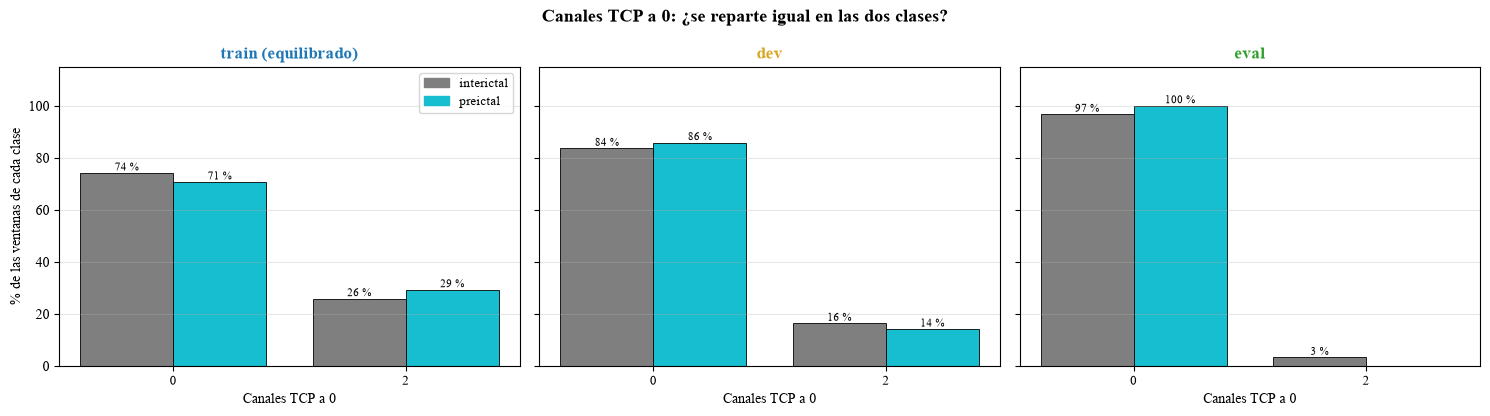

**Montaje original**: % de las ventanas de cada clase

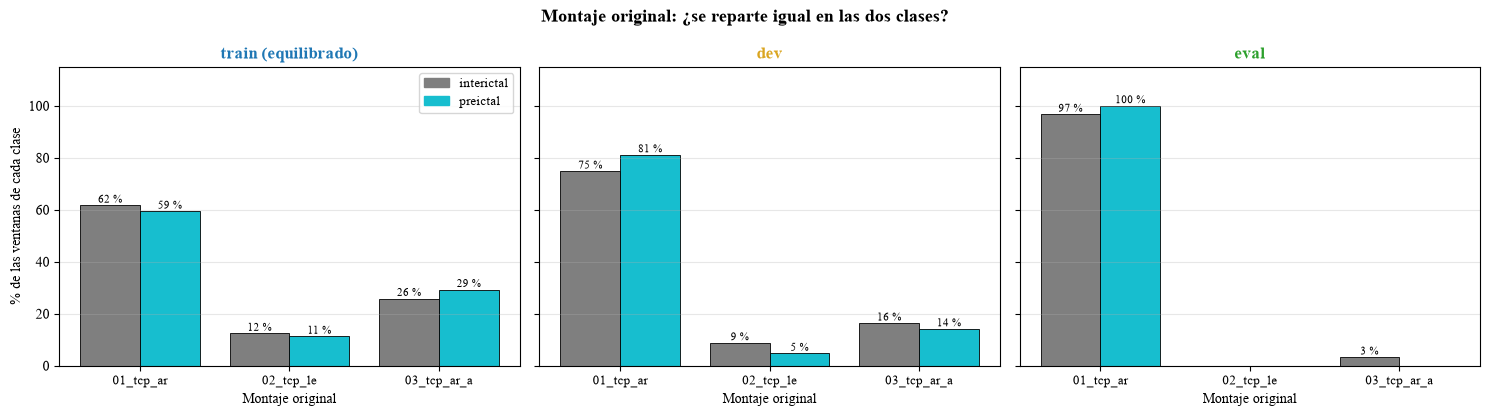

**Frecuencia original (Hz)**: % de las ventanas de cada clase

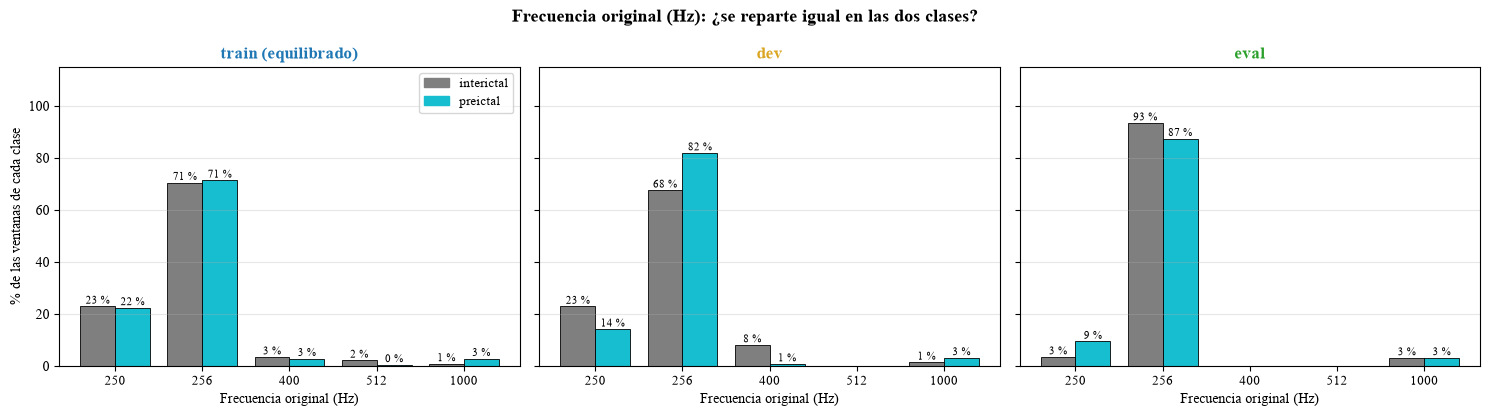

#### 🧾 Veredicto H1 y H2 (calculado con los datos)
- `canales_a_cero`: **🟢 no separa** · fuerza dentro del paciente (train) **0.52** · global: 🔵 train 0.52 · 🟡 dev 0.51 · 🟢 eval 0.52 · más alta en ⏳ preictal (train)
- `montaje`: **🟢 no separa** · fuerza dentro del paciente (train) **0.52** · global: 🔵 train 0.52 · 🟡 dev 0.51 · 🟢 eval 0.52 · más alta en ⏳ preictal (train)
- `fs_original_hz`: **🟢 no separa** · fuerza dentro del paciente (train) **0.53** · global: 🔵 train 0.52 · 🟡 dev 0.59 · 🟢 eval 0.53 · más alta en ⏳ preictal (train)

In [29]:
VARIABLES_H12 = ['canales_a_cero', 'montaje', 'fs_original_hz']
for variable, nombre in [('canales_a_cero', 'Canales TCP a 0'), ('montaje', 'Montaje original'), ('fs_original_hz', 'Frecuencia original (Hz)')]:
    tabla = porcentaje_por_clase(variable)
    display(Markdown(f'**{nombre}**: % de las ventanas de cada clase'))
    display(con_separadores(tabla_con_iconos(tabla)))
    figura_porcentajes(tabla, f'{nombre}: ¿se reparte igual en las dos clases?', nombre, f'h12_{variable}.png')

fuerza_h12 = fuerzas(VARIABLES_H12)
display(con_separadores(tabla_con_iconos(fuerza_h12), decimales=2))
mostrar_veredicto('H1 y H2', VARIABLES_H12, fuerza_h12)

👀 **Cómo leer las tablas y las figuras.** Dentro de cada vista, las barras grises (💤 interictal) y las cian (⏳ preictal) suman 100 % cada una. **Si las barras de las dos clases tienen la misma altura, la variable no separa nada.** La tabla de fuerzas lo resume en un número por vista. La columna **fuerza dentro del paciente** dice si la diferencia está **dentro** de los pacientes, que es la que la red puede aprovechar.

## 6. H3: nivel de señal del registro

🔎 **Qué buscamos.** Si la amplitud típica del tramo (`desviacion_mediana_uv` de **F02.02**) es distinta en una clase.

🤔 **Por qué.** Un registro más "ruidoso" o con más amplitud en una clase sería una pista que no tiene que ver con la crisis.

🎯 **Qué esperamos.** Diferencias pequeñas. Y aunque las hubiera, la **normalización por ventana** (`normalizacion.py`) borra casi toda la amplitud absoluta antes de que la red vea la ventana.

> ⚠️ Es una medida **del tramo**, no de la ventana: los tramos 💤 interictales suelen ser ficheros enteros y los ⏳ preictales, unos minutos. Por eso no se usa la amplitud **máxima**, que crece con la duración del tramo: mezclaría duración con amplitud.

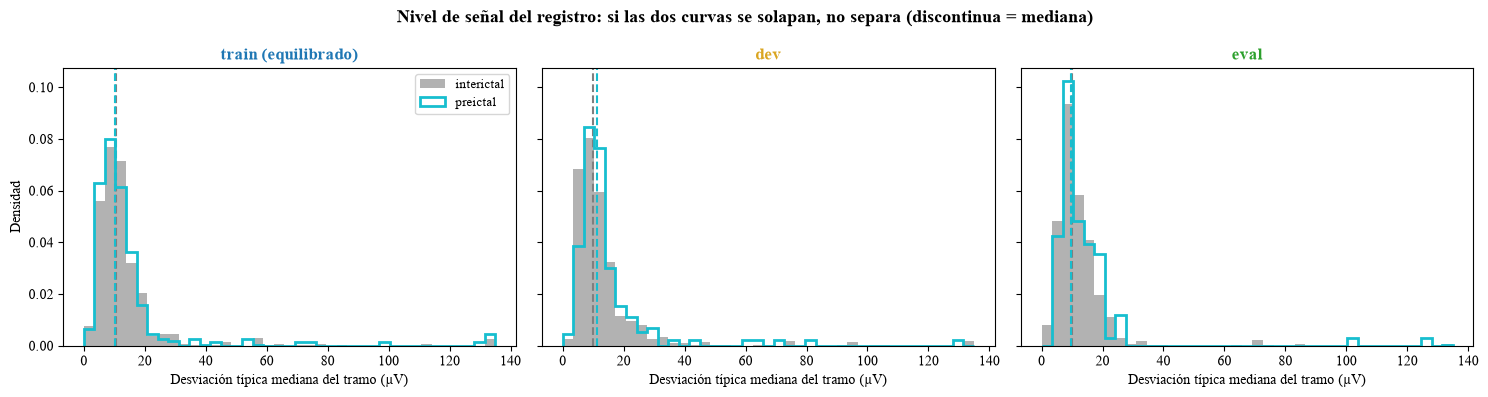

#### 🧾 Veredicto H3 (calculado con los datos)
- `nivel_senal_uv`: **🟡 separa un poco** · fuerza dentro del paciente (train) **0.56** · global: 🔵 train 0.57 · 🟡 dev 0.54 · 🟢 eval 0.59 · igual (train)

Recuerda: la red ve cada ventana **normalizada por canal**, así que esta pista le llega muy atenuada.

In [30]:
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(vistas), figsize=(5 * len(vistas), 4), sharey=True)
    axes = np.atleast_1d(axes)
    techo = ventanas.nivel_senal_uv.quantile(0.99)
    bordes = np.linspace(0, techo, 40)
    for ax, s in zip(axes, vistas):
        v = vistas[s]
        for clase in ['interictal', 'preictal']:
            x = v.loc[v.clase == clase, 'nivel_senal_uv'].clip(upper=techo)
            ax.hist(x, bins=bordes, density=True, histtype='stepfilled' if clase == 'interictal' else 'step',
                    color=COLORES_PERIODO[clase], alpha=0.6 if clase == 'interictal' else 1, lw=2, label=clase)
            ax.axvline(x.median(), color=COLORES_PERIODO[clase], ls='--', lw=1.5)
        ax.set_title(f'{s}' + (' (equilibrado)' if s == 'train' else ''), color=COLORES_SPLIT[s], fontweight='bold')
        ax.set_xlabel('Desviación típica mediana del tramo (µV)')
    axes[0].set_ylabel('Densidad')
    axes[0].legend(fontsize=9)
    fig.suptitle('Nivel de señal del registro: si las dos curvas se solapan, no separa (discontinua = mediana)', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'h3_nivel_senal.png', dpi=150, bbox_inches='tight')
    plt.show()

fuerza_h3 = fuerzas(['nivel_senal_uv'])
display(con_separadores(tabla_con_iconos(fuerza_h3), decimales=2))
mostrar_veredicto('H3', ['nivel_senal_uv'], fuerza_h3,
                  'Recuerda: la red ve cada ventana **normalizada por canal**, así que esta pista le llega muy atenuada.')

👀 **Cómo leer la figura.** Un panel por vista. En gris relleno, la distribución de 💤 interictal; en cian, la de ⏳ preictal; las líneas discontinuas son sus medianas. **Curvas encima la una de la otra = no separa.** Se corta en el percentil 99 para que se vea la zona donde están casi todas las ventanas.

## 7. H4: posición en el fichero (el sospechoso principal)

🔎 **Qué buscamos.** En qué **minuto del fichero EDF** empieza cada ventana, por clase.

🤔 **Por qué.** En TUSZ, las crisis suelen aparecer **pronto dentro de su fichero**: los ficheros con crisis se cortan cerca de ellas. Para predecir hace falta **lead-in** (minutos sin crisis antes, dentro del mismo fichero), y aun así la crisis queda a pocos minutos del principio: su ⏳ preictal cae en los primeros minutos. El 💤 interictal, en cambio, sale de ficheros enteros.

¿Lo puede notar la red? Solo si el EEG de esa parte del fichero es distinto. **Ojo**: un fichero de TUSZ es un *token*, y solo el primero de cada sesión (`t000`) es el principio real de la grabación (electrodos recién puestos, paciente despierto...). La tabla de abajo dice qué parte de cada clase está en un `t000`. Que la posición separe **no prueba** que la red la use: eso lo dirá el control de la sección 11.

🎯 **Qué esperamos.** 🔴 ⏳ preictal **concentrado al principio** del fichero, también **dentro de cada paciente**. Es el atajo más probable.

![Por qué el preictal sale al principio del fichero](img/posicion_en_fichero.png)

👀 **Qué enseña.** En TUSZ las crisis suelen estar pronto dentro de su fichero, así que su ⏳ cae en los primeros minutos; el 💤 sale de ficheros enteros. Que la posición separe **no prueba** que la red la use: eso lo dirá el control de la sección 11.

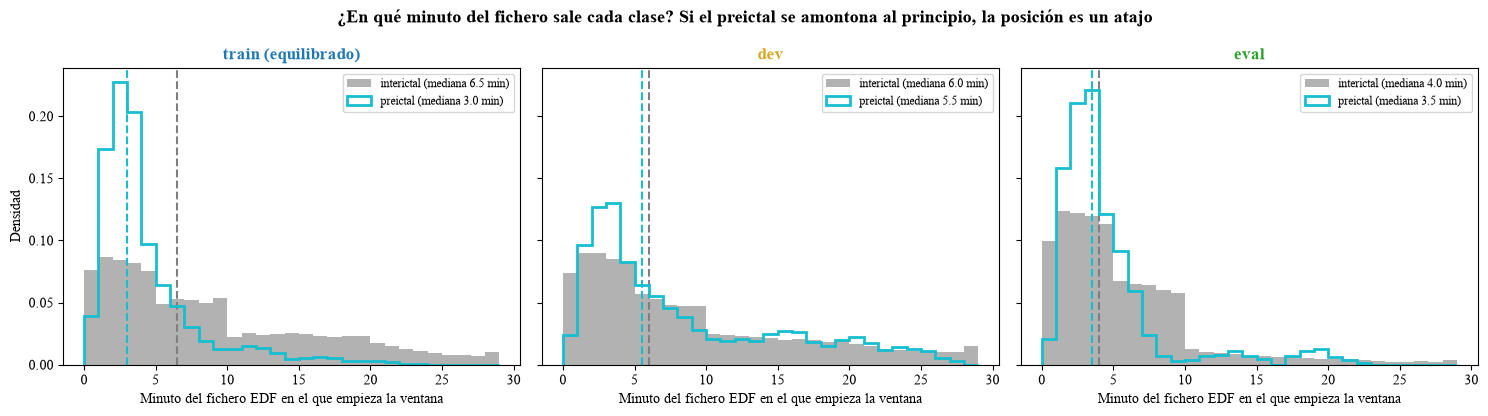

,💤 interictal: mediana (min),⏳ preictal: mediana (min),💤 interictal: % en los 5 primeros min,⏳ preictal: % en los 5 primeros min,💤 interictal: % en el primer fichero de la sesión (t000),⏳ preictal: % en el primer fichero de la sesión (t000)
vista,,,,,,
🔵 train,"6,5","3,0","40,3","74,2","18,6","18,2"
🟡 dev,"6,0","5,5","41,9","46,0","23,3","17,3"
🟢 eval,"4,0","3,5","57,8","73,2","10,2","8,4"


#### 🧾 Veredicto H4 (calculado con los datos)
- `minuto_en_fichero`: **🔴 separa mucho** · fuerza dentro del paciente (train) **0.75** · global: 🔵 train 0.74 · 🟡 dev 0.55 · 🟢 eval 0.65 · más baja en ⏳ preictal (train)

🔴 **El sesgo de posición existe**: la posición separa las clases. También separa **dentro del paciente** (fuerza 0.75), así que el equilibrado por paciente **no** la neutraliza. Que la red lo **aproveche** depende de si se nota en el EEG: se comprobará con el control de la sección 11.

In [31]:
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(vistas), figsize=(5 * len(vistas), 4.2), sharey=True)
    axes = np.atleast_1d(axes)
    maximo = np.ceil(ventanas.minuto_en_fichero.quantile(0.995))
    bordes = np.arange(0, maximo + ANCHO_FRANJA_MIN, ANCHO_FRANJA_MIN)
    for ax, s in zip(axes, vistas):
        v = vistas[s]
        for clase in ['interictal', 'preictal']:
            x = v.loc[v.clase == clase, 'minuto_en_fichero']
            ax.hist(x, bins=bordes, density=True, histtype='stepfilled' if clase == 'interictal' else 'step',
                    color=COLORES_PERIODO[clase], alpha=0.6 if clase == 'interictal' else 1, lw=2, label=f'{clase} (mediana {x.median():.1f} min)')
            ax.axvline(x.median(), color=COLORES_PERIODO[clase], ls='--', lw=1.5)
        ax.set_title(f'{s}' + (' (equilibrado)' if s == 'train' else ''), color=COLORES_SPLIT[s], fontweight='bold')
        ax.set_xlabel('Minuto del fichero EDF en el que empieza la ventana')
        ax.legend(fontsize=8.5)
    axes[0].set_ylabel('Densidad')
    fig.suptitle('¿En qué minuto del fichero sale cada clase? Si el preictal se amontona al principio, la posición es un atajo',
                 fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'h4_posicion_en_fichero.png', dpi=150, bbox_inches='tight')
    plt.show()

def resumen_posicion(v):
    return pd.Series({f'{ICONO_CLASE[c]} {c}: mediana (min)': v.loc[v.clase == c, 'minuto_en_fichero'].median() for c in ['interictal', 'preictal']}
                     | {f'{ICONO_CLASE[c]} {c}: % en los 5 primeros min': 100 * (v.loc[v.clase == c, 'minuto_en_fichero'] < 5).mean()
                        for c in ['interictal', 'preictal']})
def en_t000(v):
    return pd.Series({f'{ICONO_CLASE[c]} {c}: % en el primer fichero de la sesión (t000)':
                      100 * v.loc[v.clase == c, 'file'].str.endswith('_t000').mean() for c in ['interictal', 'preictal']})
tabla_posicion = pd.DataFrame({s: pd.concat([resumen_posicion(v), en_t000(v)]) for s, v in vistas.items()}).T
tabla_posicion.index.name = 'vista'
display(con_separadores(tabla_con_iconos(tabla_posicion)))

fuerza_h4 = fuerzas(['minuto_en_fichero'])
display(con_separadores(tabla_con_iconos(fuerza_h4), decimales=2))
luz_h4, _ = veredicto(fuerza_h4, 'minuto_en_fichero')
dentro_h4 = fuerza_h4.loc['minuto_en_fichero', ('train', 'fuerza dentro del paciente')]
texto_dentro = (f'También separa **dentro del paciente** (fuerza {dentro_h4:.2f}), así que el equilibrado por paciente **no** la neutraliza.'
                if dentro_h4 >= FUERZA_DEBIL else
                f'Dentro del paciente apenas separa (fuerza {dentro_h4:.2f}): la diferencia es sobre todo **entre** pacientes y el equilibrado la diluye.')
mostrar_veredicto('H4', ['minuto_en_fichero'], fuerza_h4,
                  {'🔴': '🔴 **El sesgo de posición existe**: la posición separa las clases. ', '🟡': '🟡 **Hay algo de sesgo de posición**. ',
                   '🟢': '🟢 **No hay sesgo de posición** con estos datos. '}[luz_h4[0]]
                  + texto_dentro + ('' if luz_h4.startswith('🟢') else ' Que la red lo **aproveche** depende de si se nota en el EEG: '
                                    'se comprobará con el control de la sección 11.'))

👀 **Cómo leer la figura.** Un panel por vista, con franjas de `ANCHO_FRANJA_MIN` minutos. Si la curva cian (⏳ preictal) está **desplazada a la izquierda** de la gris (💤 interictal), las preictales salen antes en el fichero. La leyenda da las medianas y la tabla, qué parte de cada clase cae en los **5 primeros minutos**.

## 8. H5: tipo de fichero (con crisis o sin crisis) y su duración

🔎 **Qué buscamos.** Si las ventanas de cada clase salen de **ficheros con crisis** o **sin crisis**, y si los ficheros tienen duraciones distintas.

🤔 **Por qué.** En `01_seleccion` el 💤 interictal se toma sobre todo de ficheros **sin ninguna crisis** (lo más seguro para que sea "normal"), y el ⏳ preictal sale, por definición, de ficheros **con crisis**. Si el día de una crisis el EEG es distinto (falta de sueño, cambio de medicación, ingreso en UCI), la red podría aprender "día con crisis" en lugar de "se acerca una crisis".

🎯 **Qué esperamos.** 🔴 Una separación **casi total** en `fichero_con_crisis`, **por construcción**. Esta variable no dice si la red hace trampa: dice que **no podemos descartarlo** con estos datos. La **duración del fichero** también puede separar: ficheros con y sin crisis suelen durar distinto, así que es otra forma de "reconocer el fichero". Por eso la sección 12 prepara un **control con 💤 de la misma sesión** que la crisis.

![La confusión por tipo de fichero](img/tipo_de_fichero.png)

👀 **Qué enseña.** Una **sesión** es una visita de grabación (≈ un día) y se lee en el nombre del fichero (paciente_sesión_token). Todo el ⏳ sale de sesiones con crisis y casi todo el 💤 de sesiones sin crisis, así que la red podría aprender "día con crisis" en vez de "se acerca una crisis". No es un dato nuevo: sale de `tramos.csv` (columna `origen`) y de `edfs.csv`, que `marcar_sesiones` combina al vuelo. La red no ve los metadatos; si la diferencia existe va dentro de la señal, y solo el control de la sección 12 lo puede medir.

**De qué ficheros sale cada clase** (% de las ventanas de cada clase)

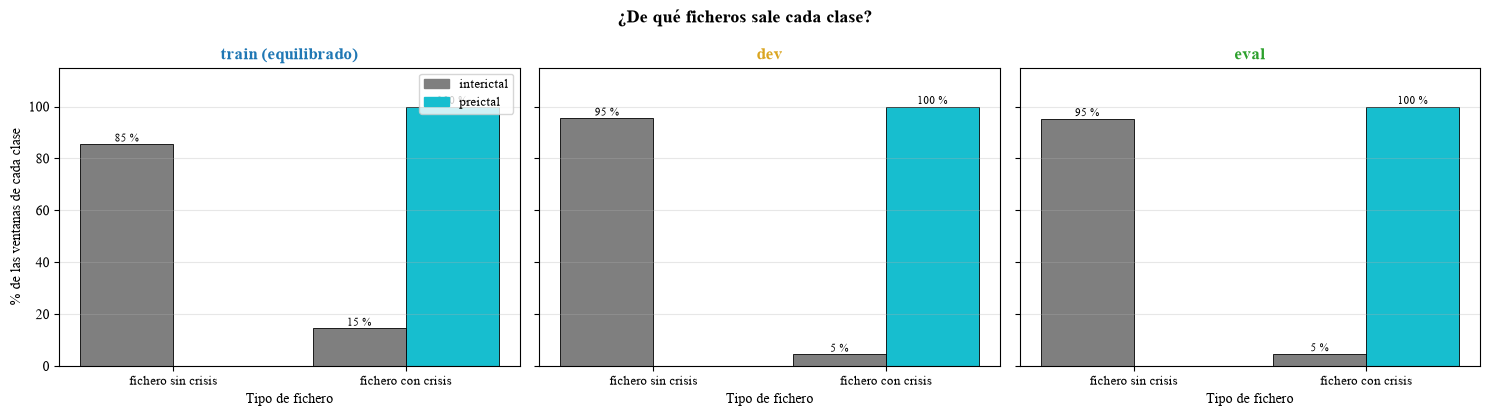

#### 🧾 Veredicto H5 (calculado con los datos)
- `fichero_con_crisis`: **🔴 separa mucho** · fuerza dentro del paciente (train) **0.93** · global: 🔵 train 0.93 · 🟡 dev 0.98 · 🟢 eval 0.98 · más alta en ⏳ preictal (train)
- `duracion_fichero_min`: **🔴 separa mucho** · fuerza dentro del paciente (train) **0.73** · global: 🔵 train 0.73 · 🟡 dev 0.51 · 🟢 eval 0.66 · más alta en ⏳ preictal (train)

⚠️ `fichero_con_crisis` separa **por cómo se eligieron los datos**, no porque la red lo vea. Lo que hay que averiguar es si la red distingue "fichero con crisis" en el EEG: eso solo lo dirá el **control de la sección 12** en la Fase 3.

In [32]:
VARIABLES_H5 = ['fichero_con_crisis', 'duracion_fichero_min']
tabla_origen = porcentaje_por_clase('fichero_con_crisis', categorias=[0, 1]).rename(index={0: 'fichero sin crisis', 1: 'fichero con crisis'})
display(Markdown('**De qué ficheros sale cada clase** (% de las ventanas de cada clase)'))
display(con_separadores(tabla_con_iconos(tabla_origen)))
figura_porcentajes(tabla_origen, '¿De qué ficheros sale cada clase?', 'Tipo de fichero', 'h5_tipo_de_fichero.png')

fuerza_h5 = fuerzas(VARIABLES_H5)
display(con_separadores(tabla_con_iconos(fuerza_h5), decimales=2))
mostrar_veredicto('H5', VARIABLES_H5, fuerza_h5,
                  '⚠️ `fichero_con_crisis` separa **por cómo se eligieron los datos**, no porque la red lo vea. Lo que hay que averiguar es si la red '
                  'distingue "fichero con crisis" en el EEG: eso solo lo dirá el **control de la sección 12** en la Fase 3.')

👀 **Cómo leer la tabla y la figura.** Si casi todo el 💤 interictal es "fichero sin crisis" y todo el ⏳ preictal "fichero con crisis", las clases están **mezcladas con el tipo de fichero** (confusión, *confounding*). La duración del fichero se lee igual que el resto de variables: fuerza cerca de 0,5 = no separa.

## 9. El semáforo: todas las variables juntas → `auditoria_variables.csv`

Una fila por variable con su fuerza en cada vista y la fuerza **dentro del paciente** (train), que es la que **decide el semáforo**. Es el resumen de las secciones 5 a 8.

💾 **Guardado `auditoria_variables.csv`** · 2 KB · 7 filas × 13 columnas  
*Qué guarda:* una fila por variable de atajo: su AUROC, fuerza y dirección en cada vista, la fuerza dentro del paciente en train, si la red la ve directamente y su semáforo (decidido por la fuerza dentro del paciente en train). *Abajo:* las 5 primeras filas.

,variable,🔵 train_AUROC,🔵 train_fuerza,🔵 train_dirección,🟡 dev_AUROC,🟡 dev_fuerza,🟡 dev_dirección,🟢 eval_AUROC,🟢 eval_fuerza,🟢 eval_dirección,🔵 train_fuerza_dentro_del_paciente,resumen_la_red_la_ve,resumen_semáforo
0,fichero_con_crisis,0.927485,0.927485,más alta en ⏳ preictal,0.977496,0.977496,más alta en ⏳ preictal,0.976524,0.976524,más alta en ⏳ preictal,0.927485,no (solo si deja huella),🔴 separa mucho
1,minuto_en_fichero,0.313152,0.738353,más baja en ⏳ preictal,0.487414,0.548216,más baja en ⏳ preictal,0.442319,0.646299,más baja en ⏳ preictal,0.753413,no (solo si deja huella),🔴 separa mucho
2,duracion_fichero_min,0.524765,0.731329,más alta en ⏳ preictal,0.679204,0.511258,más alta en ⏳ preictal,0.809418,0.664692,más alta en ⏳ preictal,0.731323,no (solo si deja huella),🔴 separa mucho
3,nivel_senal_uv,0.496654,0.568409,igual,0.563864,0.540651,más alta en ⏳ preictal,0.530210,0.588931,más alta en ⏳ preictal,0.560386,sí,🟡 separa un poco
4,fs_original_hz,0.524238,0.524238,más alta en ⏳ preictal,0.589969,0.589969,más alta en ⏳ preictal,0.471334,0.528666,más baja en ⏳ preictal,0.527564,sí,🟢 no separa


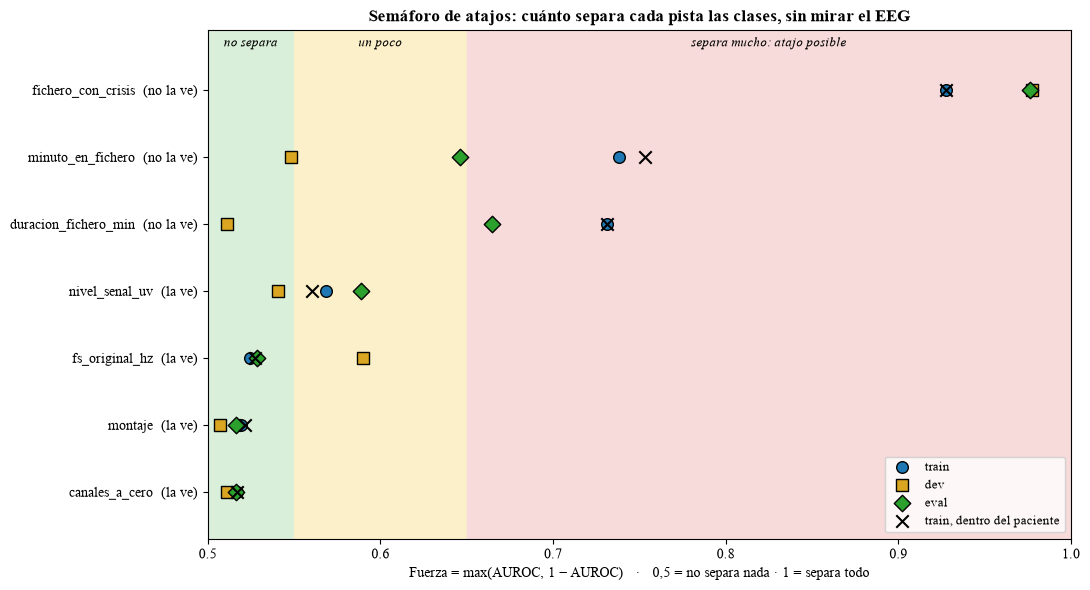

In [33]:
auditoria = fuerzas(VARIABLES)
auditoria[('resumen', '¿la red la ve?')] = ['sí' if VARIABLES_ATAJO[v][3] else 'no (solo si deja huella)' for v in auditoria.index]
auditoria[('resumen', 'semáforo')] = [veredicto(auditoria, v)[0] for v in auditoria.index]
orden = auditoria[CRITERIO].astype(float).sort_values(ascending=False).index
auditoria = auditoria.loc[orden]

plana = auditoria.copy()
plana.columns = [f'{a}_{b}'.replace(' ', '_').replace('¿', '').replace('?', '') for a, b in plana.columns]
plana.to_csv(RUTA_RESULTADOS / 'auditoria_variables.csv')
mostrar_fichero(RUTA_RESULTADOS / 'auditoria_variables.csv',
                'una fila por variable de atajo: su AUROC, fuerza y dirección en cada vista, la fuerza dentro del paciente en train, '
                'si la red la ve directamente y su semáforo (decidido por la fuerza dentro del paciente en train)')
display(con_separadores(tabla_con_iconos(auditoria), decimales=2))

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(auditoria) + 1.8))
    ax.axvspan(0.5, FUERZA_DEBIL, color='#d9efd9', zorder=0)
    ax.axvspan(FUERZA_DEBIL, FUERZA_FUERTE, color='#fbf0c9', zorder=0)
    ax.axvspan(FUERZA_FUERTE, 1.0, color='#f7dada', zorder=0)
    y = np.arange(len(auditoria))[::-1]
    marcadores = {'train': 'o', 'dev': 's', 'eval': 'D'}
    for s in vistas:
        ax.scatter(auditoria[(s, 'fuerza')], y, marker=marcadores[s], s=70, color=COLORES_SPLIT[s], edgecolor='black', zorder=3, label=s)
    ax.scatter(auditoria[('train', 'fuerza dentro del paciente')], y, marker='x', s=80, color='black', zorder=4,
               label='train, dentro del paciente')
    ax.set_yticks(y, [f'{v}  ({"la ve" if VARIABLES_ATAJO[v][3] else "no la ve"})' for v in auditoria.index])
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel('Fuerza = max(AUROC, 1 − AUROC)   ·   0,5 = no separa nada · 1 = separa todo')
    for x, texto in [((0.5 + FUERZA_DEBIL) / 2, 'no separa'), ((FUERZA_DEBIL + FUERZA_FUERTE) / 2, 'un poco'),
                     ((FUERZA_FUERTE + 1) / 2, 'separa mucho: atajo posible')]:
        ax.text(x, len(auditoria) - 0.35, texto, ha='center', fontsize=9.5, style='italic')
    ax.set_ylim(-0.7, len(auditoria) - 0.1)
    ax.legend(fontsize=9, loc='lower right')
    ax.set_title('Semáforo de atajos: cuánto separa cada pista las clases, sin mirar el EEG', fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'semaforo_variables.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una fila por variable (entre paréntesis, si la red la ve directamente). Cada punto es su fuerza en una vista: ● train equilibrado, ■ dev, ◆ eval. La **✕ es la fuerza dentro del paciente en train y es la que decide el semáforo**: la zona donde cae dice si es verde (no separa), amarillo (un poco) o **rojo (atajo que la red puede aprender)**. Los ■ y ◆ son informativos: si caen lejos de la ✕, la diferencia está **entre** pacientes de dev o eval, no dentro.

## 10. ¿Puede un modelo acertar SOLO con metadatos? El techo del atajo → `modelo_metadatos.csv`

Una variable sola puede separar poco, y varias juntas, bastante más. Se entrenan modelos sencillos que **no ven la señal**, solo las variables de atajo, con 🔵 **train equilibrado**, y se miden en 🟡 dev y 🟢 eval. Se hace en **tres escalones**, de menos a más pistas:

| Escalón | Variables | Qué representa |
|---|---|---|
| **1 · lo que la red ve** | canales a 0, montaje, Hz originales, nivel de señal | Atajos que están **en la propia ventana** |
| **2 · + posición** | escalón 1 + minuto en el fichero (a 30 s) | Lo anterior + la posición. Es el **techo del atajo realista**: lo máximo que podría ganar la red si notara perfectamente en el EEG en qué parte del fichero está |
| **3 · + contexto del fichero** | escalón 2 + duración del fichero + fichero con crisis | **Techo teórico**: nada de esto cabe en una ventana de 4 s (la duración junto al minuto dice cuánto falta para que acabe la grabación; el tipo de fichero separa por construcción, H5). Solo sirve de referencia |

Cada escalón se prueba con dos modelos: **regresión logística** (relaciones simples) y **árboles** (`HistGradientBoosting`, capta combinaciones y umbrales).

**Control negativo.** El mismo modelo del escalón 2 con las etiquetas **barajadas dentro de cada paciente**. Tiene que dar ~0,5. Si no, algo se cuela en el procedimiento. Un solo barajado puede salir algo alto por azar (un árbol "memoriza" ruido), así que se promedian `N_BARAJADOS` modelos con barajados distintos.

**Intervalo de confianza.** Bootstrap **por paciente** (`auroc_con_intervalo`): se sortean pacientes, no ventanas, porque las ventanas de un mismo paciente no son independientes.

**Qué esperamos.** Escalón 1 cerca de 0,5 (el equilibrado por paciente lo diluye). Escalón 2 por encima, por la posición. Escalón 3 casi 1, por construcción.

> ⚠️ **Cómo NO leerlo.** No es un "suelo" que la red tenga que superar: la red no lee el minuto del fichero, solo podría notarlo si el EEG de esa parte es distinto. Es un **techo**: cuánto podría inflar la nota la pista como mucho. Que la red lo use o no se sabrá comparando su nota en el conjunto normal y en los **controles** (secciones 11 y 12).

> ⏱️ Tarda unos minutos: el bootstrap repite la AUROC `N_BOOTSTRAP` veces por modelo y partición.

![El techo del atajo](img/techo_del_atajo.png)

👀 **Qué enseña.** Se entrenan modelos que **no ven el EEG**, solo las pistas, en tres escalones. El escalón 2 es el techo del atajo: lo máximo que la posición podría inflar la nota de la red; no es una nota que la red tenga que superar. **Las cifras reales** de cada escalón las da esta sección al ejecutarla (figura `techo_del_atajo.png`, recuadro 🏆 y `modelo_metadatos.csv`); la prueba de verdad es la nota de la red en los controles.

![Bootstrap por paciente](img/bootstrap_por_paciente.png)

👀 **Qué enseña.** El **bootstrap** estima cuánto nos podemos fiar de una AUROC: se hace una muestra nueva sorteando **con reemplazo** (un elemento puede salir dos veces y otro ninguna), se recalcula la AUROC y se repite 500 veces; el intervalo va del percentil 2,5 al 97,5. **Por paciente** significa que se sortean pacientes enteros con todas sus ventanas, porque las ventanas de un mismo paciente se parecen mucho y sortearlas sueltas daría un intervalo falsamente estrecho.

In [34]:
ESCALONES = {
    '1 · lo que la red ve': ['canales_a_cero', 'nivel_senal_uv', 'montaje', 'fs_original_hz'],
    '2 · + posición': ['canales_a_cero', 'nivel_senal_uv', 'montaje', 'fs_original_hz', 'minuto_en_fichero'],
    '3 · + contexto del fichero': ['canales_a_cero', 'nivel_senal_uv', 'montaje', 'fs_original_hz', 'minuto_en_fichero',
                                   'duracion_fichero_min', 'fichero_con_crisis'],
}
MODELOS = {'logística': lambda: LogisticRegression(max_iter=2000),
           'árboles': lambda: HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA)}

def modelo_de_metadatos(variables, tipo):
    """Modelo que solo ve metadatos: las numéricas se estandarizan y las de categorías se pasan a columnas 0/1."""
    numericas = [v for v in variables if VARIABLES_ATAJO[v][2] == 'numerica']
    categoricas = [v for v in variables if VARIABLES_ATAJO[v][2] == 'categorica']
    preparacion = ColumnTransformer([('numericas', StandardScaler(), numericas),
                                     ('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)])
    return make_pipeline(preparacion, MODELOS[tipo]())

N_BARAJADOS = 5   # modelos con etiquetas barajadas que se promedian en el control negativo

def etiquetas_barajadas(v, semilla=SEMILLA):
    """Etiquetas barajadas DENTRO de cada paciente: mantiene cuántas ⏳ y 💤 tiene cada uno, pero rompe la relación con las variables."""
    rng = np.random.default_rng(semilla)
    return v.groupby('patient').etiqueta.transform(lambda e: rng.permutation(e.to_numpy()))

entrenamiento = vistas['train']
evaluar_en = [s for s in ['dev', 'eval'] if s in vistas]
filas, inicio = [], time.time()
pruebas = [(e, t, False) for e in ESCALONES for t in MODELOS] + [('2 · + posición', 'árboles', True)]
for escalon, tipo, barajado in pruebas:
    variables = ESCALONES[escalon]
    semillas = [SEMILLA + k for k in range(N_BARAJADOS)] if barajado else [None]
    modelos = []
    for semilla in semillas:
        y = etiquetas_barajadas(entrenamiento, semilla) if barajado else entrenamiento.etiqueta
        modelos.append(modelo_de_metadatos(variables, tipo).fit(entrenamiento[variables], y))
    for s in evaluar_en:
        v = vistas[s]
        puntuacion = np.mean([m.predict_proba(v[variables])[:, 1] for m in modelos], axis=0)   # media de los barajados
        auroc, inferior, superior = auroc_con_intervalo(v.etiqueta, puntuacion, v.patient, n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        filas.append({'escalón': escalon + (' (control: etiquetas barajadas)' if barajado else ''), 'modelo': tipo, 'split': s,
                      'auroc': auroc, 'ic95_inferior': inferior, 'ic95_superior': superior, 'pacientes': v.patient.nunique()})
print(f'{len(pruebas)} modelos × {len(evaluar_en)} particiones en {time.time() - inicio:.0f} s')

resultados = pd.DataFrame(filas)
resultados.to_csv(RUTA_RESULTADOS / 'modelo_metadatos.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'modelo_metadatos.csv',
                'una fila por escalón, modelo y partición: la AUROC de un modelo que SOLO ve metadatos y su intervalo del 95 % '
                '(bootstrap por paciente). El escalón con etiquetas barajadas es el control negativo')
tabla_modelos = resultados.pivot_table(index=['escalón', 'modelo'], columns='split', values=['auroc', 'ic95_inferior', 'ic95_superior'], sort=False)
tabla_modelos = tabla_modelos.swaplevel(axis=1).reindex(columns=evaluar_en, level=0)
display(con_separadores(tabla_con_iconos(tabla_modelos), decimales=2))

7 modelos × 2 particiones en 60 s


💾 **Guardado `modelo_metadatos.csv`** · 1,5 KB · 14 filas × 7 columnas  
*Qué guarda:* una fila por escalón, modelo y partición: la AUROC de un modelo que SOLO ve metadatos y su intervalo del 95 % (bootstrap por paciente). El escalón con etiquetas barajadas es el control negativo. *Abajo:* las 5 primeras filas.

,escalón,modelo,split,auroc,ic95_inferior,ic95_superior,pacientes
0,1 · lo que la red ve,logística,🟡 dev,0.566000,0.457635,0.640932,36
1,1 · lo que la red ve,logística,🟢 eval,0.513885,0.409671,0.618623,30
2,1 · lo que la red ve,árboles,🟡 dev,0.585352,0.529722,0.648807,36
3,1 · lo que la red ve,árboles,🟢 eval,0.479997,0.426108,0.534275,30
4,2 · + posición,logística,🟡 dev,0.521406,0.477670,0.588985,36


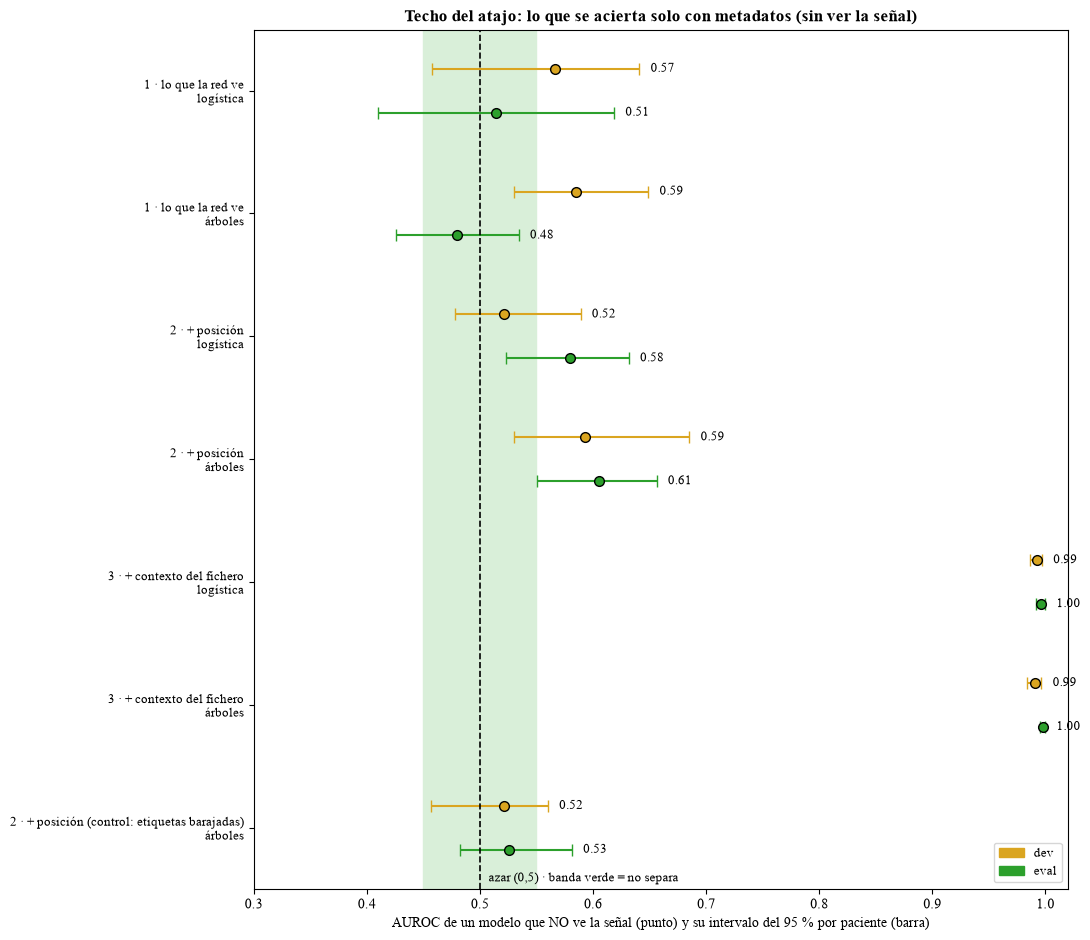

In [35]:
# Figura: AUROC de cada modelo de metadatos con su intervalo, en dev y eval
with plt.rc_context(ESTILO_TIMES):
    etiquetas = list(dict.fromkeys(zip(resultados['escalón'], resultados.modelo)))
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(etiquetas) * len(evaluar_en) + 1.8))
    ax.axvspan(1 - FUERZA_DEBIL, FUERZA_DEBIL, color='#d9efd9', zorder=0)
    posiciones, nombres = [], []
    for k, (escalon, tipo) in enumerate(etiquetas):
        for j, s in enumerate(evaluar_en):
            fila = resultados[(resultados['escalón'] == escalon) & (resultados.modelo == tipo) & (resultados.split == s)].iloc[0]
            yy = -(k * (len(evaluar_en) + 0.8) + j)
            ax.errorbar(fila.auroc, yy, xerr=[[fila.auroc - fila.ic95_inferior], [fila.ic95_superior - fila.auroc]], fmt='o',
                        color=COLORES_SPLIT[s], ecolor=COLORES_SPLIT[s], capsize=4, ms=7, mec='black')
            ax.text(fila.ic95_superior + 0.01, yy, f'{fila.auroc:.2f}', va='center', fontsize=9)
        posiciones.append(-(k * (len(evaluar_en) + 0.8) + (len(evaluar_en) - 1) / 2))
        nombres.append(f'{escalon}\n{tipo}')
    ax.axvline(0.5, color='black', ls='--', lw=1.2)
    ax.text(0.505, 0.005, ' azar (0,5) · banda verde = no separa', fontsize=9, transform=ax.get_xaxis_transform(), va='bottom')
    ax.set_yticks(posiciones, nombres, fontsize=9)
    ax.set_xlim(0.3, 1.02)
    ax.set_xlabel('AUROC de un modelo que NO ve la señal (punto) y su intervalo del 95 % por paciente (barra)')
    ax.legend(handles=[Patch(color=COLORES_SPLIT[s], label=s) for s in evaluar_en], fontsize=9, loc='lower right')
    ax.set_title('Techo del atajo: lo que se acierta solo con metadatos (sin ver la señal)', fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'techo_del_atajo.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una fila por escalón y modelo, con un punto por partición (🟡 dev, 🟢 eval) y su intervalo del 95 %. La línea discontinua es el **azar** y la banda verde, "no separa". **Si un intervalo no toca la banda verde, ese modelo acierta algo sin ver el EEG.** El control barajado tiene que caer en la banda verde.

In [36]:
# Veredicto automático del techo del atajo
def fila_modelo(escalon, tipo, split):
    r = resultados[(resultados['escalón'] == escalon) & (resultados.modelo == tipo) & (resultados.split == split)]
    return r.iloc[0] if len(r) else None

split_final = 'eval' if 'eval' in evaluar_en else evaluar_en[-1]
mejor = {e: max((fila_modelo(e, t, split_final) for t in MODELOS), key=lambda f: f.auroc) for e in ESCALONES}
control_barajado = fila_modelo('2 · + posición (control: etiquetas barajadas)', 'árboles', split_final)
TECHO_VISIBLE, TECHO_POSICION = mejor['1 · lo que la red ve'], mejor['2 · + posición']

def describe(f):
    return f'**{f.auroc:.2f}** (IC 95 % {f.ic95_inferior:.2f}-{f.ic95_superior:.2f}, {f.modelo})'

control_ok = control_barajado.ic95_inferior <= 0.5 <= control_barajado.ic95_superior or abs(control_barajado.auroc - 0.5) < (FUERZA_DEBIL - 0.5)
lineas = [
    f'{semaforo(max(TECHO_VISIBLE.auroc, 1 - TECHO_VISIBLE.auroc))} **Escalón 1 · lo que la red ve**: {describe(TECHO_VISIBLE)} en {con_icono(split_final)}'
    + (': lo que está en la propia ventana no sirve para acertar.' if max(TECHO_VISIBLE.auroc, 1 - TECHO_VISIBLE.auroc) < FUERZA_DEBIL else
       ': ⚠️ lo que está en la propia ventana ya separa algo; revisar H1-H3.'),
    f'{semaforo(max(TECHO_POSICION.auroc, 1 - TECHO_POSICION.auroc))} **Escalón 2 · + posición**: {describe(TECHO_POSICION)} → es el **techo del atajo**: '
    f'lo máximo que la posición podría inflar la nota de la red (si la notara perfectamente en el EEG). No es una nota a superar.',
    f'ℹ️ **Escalón 3 · + contexto del fichero**: {describe(mejor["3 · + contexto del fichero"])}: techo teórico (no cabe en una ventana), no una medida de la red.',
    ('✅' if control_ok else '🔴') + f' **Control barajado**: {describe(control_barajado)}' +
    (' → cae en el azar: el procedimiento no tiene fugas.' if control_ok else ' → 🔴 NO cae en el azar: revisar el procedimiento antes de fiarse de nada.'),
]
mostrar_destacado('El techo del atajo', *[l.replace('**', '') for l in lineas])
display(Markdown('\n'.join(f'- {l}' for l in lineas)))

- 🟢 no separa **Escalón 1 · lo que la red ve**: **0.51** (IC 95 % 0.41-0.62, logística) en 🟢 eval: lo que está en la propia ventana no sirve para acertar.
- 🟡 separa un poco **Escalón 2 · + posición**: **0.61** (IC 95 % 0.55-0.66, árboles) → es el **techo del atajo**: lo máximo que la posición podría inflar la nota de la red (si la notara perfectamente en el EEG). No es una nota a superar.
- ℹ️ **Escalón 3 · + contexto del fichero**: **1.00** (IC 95 % 1.00-1.00, árboles): techo teórico (no cabe en una ventana), no una medida de la red.
- ✅ **Control barajado**: **0.53** (IC 95 % 0.48-0.58, árboles) → cae en el azar: el procedimiento no tiene fugas.

## 11. Remedio 1: un conjunto de control emparejado por posición → `conjuntos_control/`

**La idea.** Si la red acierta solo porque "las ⏳ preictales están al principio del fichero", basta con quitarle esa pista: se arma un conjunto en el que las 💤 interictales salen **de los mismos minutos del fichero** que las ⏳ preictales, **paciente a paciente** (`emparejar_por_posicion`).

1. Se parte cada fichero en franjas de `ANCHO_FRANJA_MIN` minutos.
2. Para cada paciente y franja, por cada ⏳ preictal se sortean `RATIO_CONTROL` 💤 interictales **suyas** de esa misma franja.
3. Así, la posición deja de separar.

**Para qué sirve en la Fase 3.** Se evalúa la red (o se reentrena) también en este conjunto. **Si su nota se mantiene, no usaba la posición; si cae, la usaba.**

🎯 **Qué esperamos.** La fuerza de `minuto_en_fichero` cerca de 0,5 en el control, a cambio de **menos ventanas** 💤 interictales, porque no todos los pacientes tienen interictal en los primeros minutos.

![Control 1: emparejado por posición](img/emparejado_por_posicion.png)

👀 **Qué enseña.** Un paciente, con el fichero en franjas de 1 minuto. Antes, el ⏳ se amontona en los minutos 1-5. En el control, por cada ⏳ se coge una 💤 del mismo paciente y de la misma franja: las dos clases quedan en los mismos minutos y la posición deja de separar. Donde faltan 💤, el control se queda con menos.

In [37]:
control_por_split, resumen_control = {}, {}
for s, v in vistas.items():
    base = ventanas[ventanas.split == s]                      # se empareja con TODAS las ventanas del conjunto, no solo las equilibradas
    mascara, cumplido = emparejar_por_posicion(base, ancho_min=ANCHO_FRANJA_MIN, ratio=RATIO_CONTROL, semilla=SEMILLA)
    c = base[mascara]
    control_por_split[s] = c
    antes = fuerza_auroc(v.etiqueta, codificar_por_franjas(vistas['train'].minuto_en_fichero, vistas['train'].etiqueta, v.minuto_en_fichero))
    despues = fuerza_auroc(c.etiqueta, codificar_por_franjas(vistas['train'].minuto_en_fichero, vistas['train'].etiqueta, c.minuto_en_fichero))
    resumen_control[s] = {'pacientes': c.patient.nunique(), '⏳ preictal': int((c.clase == 'preictal').sum()),
                          '💤 interictal': int((c.clase == 'interictal').sum()),
                          '% de 💤 interictal pedida que se consigue': 100 * cumplido,
                          'fuerza de la posición antes': antes[1], 'fuerza de la posición en el control': despues[1],
                          'semáforo en el control': semaforo(despues[1])}
# Comprobación más dura: un árbol que solo ve la posición, entrenado en el control de train. Si en el control de dev y eval
# sale ~0,5, la posición no sirve ni siquiera con "forma" (la AUROC simple solo ve "más / menos").
arbol = HistGradientBoostingClassifier(max_iter=200, random_state=SEMILLA).fit(control_por_split['train'][['minuto_en_fichero']],
                                                                                 control_por_split['train'].etiqueta)
for s, c in control_por_split.items():
    if s != 'train':
        a = fuerza_auroc(c.etiqueta, arbol.predict_proba(c[['minuto_en_fichero']])[:, 1])
        resumen_control[s]['fuerza de un árbol con la posición, en el control'] = a[1]
        resumen_control[s]['semáforo en el control'] = semaforo(max(resumen_control[s]['fuerza de la posición en el control'], a[1]))
tabla_control = pd.DataFrame(resumen_control).T
tabla_control.index.name = 'vista'
display(con_separadores(tabla_con_iconos(tabla_control), decimales=2))

control = pd.concat(control_por_split.values())
columnas = [c for c in conjunto.columns if c != 'entrenamiento_equilibrado'] + ['minuto_en_fichero']
control[columnas].to_csv(RUTA_CONTROL / f'{CONJUNTO}_emparejado_posicion.csv', index=False)
mostrar_fichero(RUTA_CONTROL / f'{CONJUNTO}_emparejado_posicion.csv',
                f'el conjunto de CONTROL de {CONJUNTO}: todas sus ⏳ preictales y, de cada paciente, {numero_legible(RATIO_CONTROL)} 💤 interictal '
                f'por cada ⏳ preictal sorteada en la misma franja de {numero_legible(ANCHO_FRANJA_MIN)} min del fichero. Mismas columnas que '
                f'conjuntos/{CONJUNTO}.csv (sin entrenamiento_equilibrado: ya está emparejado) más el minuto del fichero')

,pacientes,⏳ preictal,💤 interictal,% de 💤 interictal pedida que se consigue,fuerza de la posición antes,fuerza de la posición en el control,semáforo en el control,"fuerza de un árbol con la posición, en el control"
vista,,,,,,,,
🔵 train,93,21.984,13.603,"61,88","0,74","0,50",🟢 no separa,nan
🟡 dev,28,11.190,8.381,"74,90","0,55","0,51",🟢 no separa,"0,50"
🟢 eval,27,8.375,6.012,"71,79","0,65","0,51",🟢 no separa,"0,52"


💾 **Guardado `general_emparejado_posicion.csv`** · 13,2 MB · 69.545 filas × 13 columnas  
*Qué guarda:* el conjunto de CONTROL de general: todas sus ⏳ preictales y, de cada paciente, 1 💤 interictal por cada ⏳ preictal sorteada en la misma franja de 1 min del fichero. Mismas columnas que conjuntos/general.csv (sin entrenamiento_equilibrado: ya está emparejado) más el minuto del fichero. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,minuto_en_fichero
0,aaaaaacz_s001_t001_interictal_000000000_000230400,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,230400,NaN,15.0
1,aaaaaacz_s001_t001_interictal_000000000_000231424,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,231424,NaN,15.0
2,aaaaaacz_s001_t001_interictal_000000000_000232448,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,232448,NaN,15.0
3,aaaaaacz_s001_t001_interictal_000000000_000233472,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,233472,NaN,15.0
4,aaaaaacz_s001_t001_interictal_000000000_000234496,🔵 train,aaaaaacz,aaaaaacz_s001_t001,💤 interictal,0,nan,nan,NaN,train/interictal/aaaaaacz_s001_t001_interictal...,234496,NaN,15.0


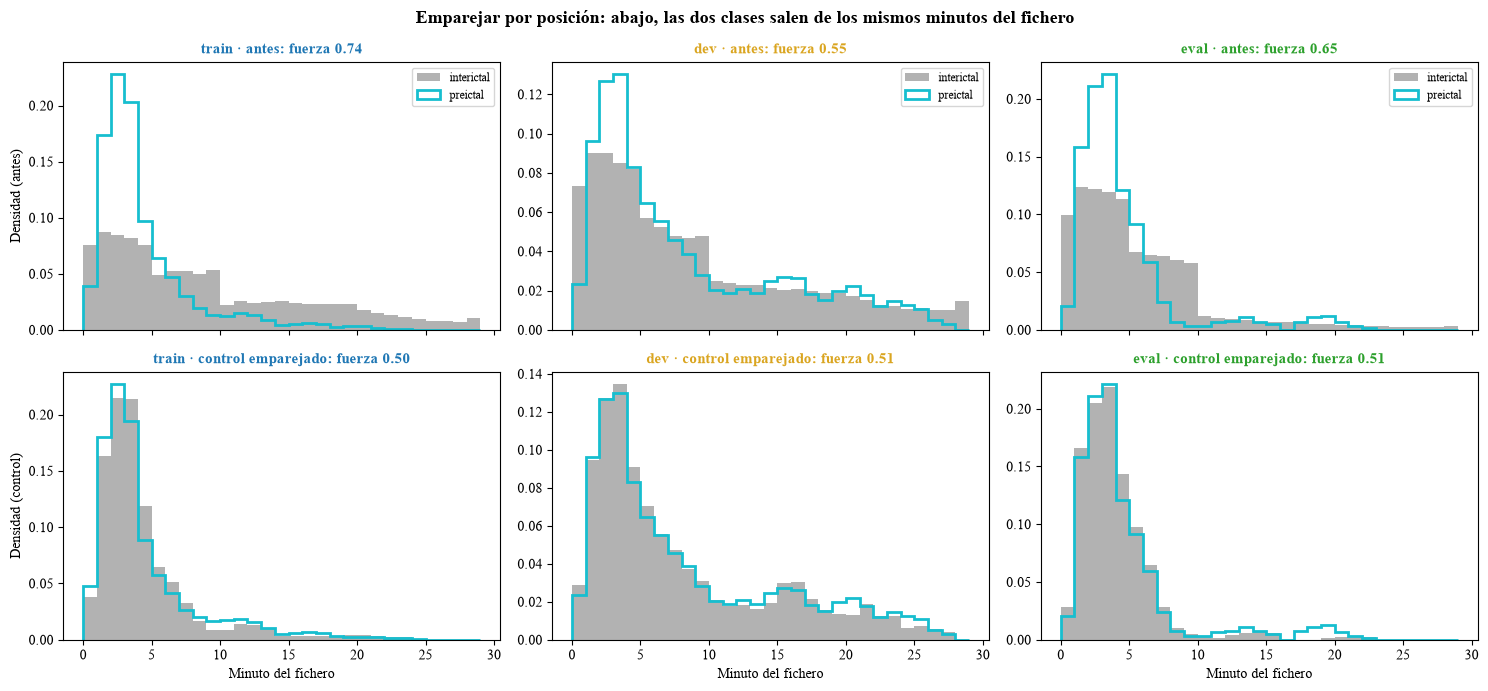

#### 🧾 Veredicto del control
- 🟢 no separa En el control, la fuerza de la posición es como mucho **0.52** (neutralizada).
- Se consigue al menos el **62 %** de las 💤 interictales pedidas: en algunas franjas faltan, así que el control tiene menos 💤 interictales que ⏳ preictales (en la Fase 3, compensar con pesos de clase).

In [38]:
# Figura: la posición antes y después de emparejar
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(2, len(vistas), figsize=(5 * len(vistas), 7), sharex=True, squeeze=False)
    maximo = np.ceil(ventanas.minuto_en_fichero.quantile(0.995))
    bordes = np.arange(0, maximo + ANCHO_FRANJA_MIN, ANCHO_FRANJA_MIN)
    for j, s in enumerate(vistas):
        for i, (datos, titulo) in enumerate([(vistas[s], 'antes'), (control_por_split[s], 'control emparejado')]):
            ax = axes[i, j]
            for clase in ['interictal', 'preictal']:
                x = datos.loc[datos.clase == clase, 'minuto_en_fichero']
                ax.hist(x, bins=bordes, density=True, histtype='stepfilled' if clase == 'interictal' else 'step',
                        color=COLORES_PERIODO[clase], alpha=0.6 if clase == 'interictal' else 1, lw=2, label=clase)
            fuerza = fuerza_auroc(datos.etiqueta, codificar_por_franjas(vistas['train'].minuto_en_fichero, vistas['train'].etiqueta,
                                                                        datos.minuto_en_fichero))[1]
            ax.set_title(f'{s} · {titulo}: fuerza {fuerza:.2f}', color=COLORES_SPLIT[s], fontweight='bold', fontsize=11)
            if i == 1:
                ax.set_xlabel('Minuto del fichero')
        axes[0, j].legend(fontsize=8.5)
    axes[0, 0].set_ylabel('Densidad (antes)')
    axes[1, 0].set_ylabel('Densidad (control)')
    fig.suptitle('Emparejar por posición: abajo, las dos clases salen de los mismos minutos del fichero', fontsize=13, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'control_posicion.png', dpi=150, bbox_inches='tight')
    plt.show()

fuerza_control_max = tabla_control[[c for c in tabla_control.columns if c.startswith('fuerza') and 'control' in c]].astype(float).max().max()
cumplido_min = tabla_control['% de 💤 interictal pedida que se consigue'].min()
display(Markdown(
    (f'#### 🧾 Veredicto del control\n- {semaforo(fuerza_control_max)} En el control, la fuerza de la posición es como mucho **{fuerza_control_max:.2f}** '
     f'({"neutralizada" if fuerza_control_max < FUERZA_DEBIL else "reducida, pero no del todo"}).\n'
     f'- Se consigue al menos el **{cumplido_min:.0f} %** de las 💤 interictales pedidas'
     + (': en algunas franjas faltan, así que el control tiene menos 💤 interictales que ⏳ preictales (en la Fase 3, compensar con pesos de clase).'
        if cumplido_min < 95 else '.'))))

👀 **Cómo leer la tabla y la figura.** Arriba, las vistas tal como están: la curva cian (⏳ preictal) desplazada respecto a la gris (💤 interictal). Abajo, el **control**: las dos curvas tienen que **coincidir**. El título de cada panel da la fuerza de la posición: en el control debería acercarse a 0,5. En la tabla, la columna del **árbol** es la prueba más dura: un modelo que solo ve la posición, entrenado en el propio control, tampoco debe acertar. El % conseguido dice cuántas de las 💤 interictales pedidas había de verdad en esas franjas.

> ⚠️ El control **no sustituye** a los conjuntos de **F02.04**: es un experimento aparte para la Fase 3. En dev y eval cambia el desbalance real, así que con él **no se calculan falsas alarmas por hora**, solo AUROC.

## 12. Remedio 2: un control de tipo de fichero → `conjuntos_control/`

**La idea.** Para saber si la red aprende "día con crisis" (H5) en vez de "se acerca una crisis", hace falta 💤 interictal **de un día con crisis**, pero lejos de ella. Si la red mantiene su nota con ese 💤, no usaba el tipo de fichero.

**Primera opción (se comprueba y se descarta si no sirve): el 💤 de ficheros con crisis.** `01_seleccion` ya guarda 💤 de ficheros con crisis, lejos de ellas (origen `lejos_de_crisis`). Pero hay que mirar **dónde** está: si casi todo cae justo **después** de la crisis, ese EEG puede seguir alterado (lentitud postictal más allá del margen de 5 min), y el control mezclaría dos cosas.

**Segunda opción: 💤 de la misma sesión.** Ficheros **sin** crisis de una **sesión que sí tiene crisis** (mismo paciente, mismo día). Variante estricta: solo ficheros (*tokens*) **anteriores** al primer fichero con crisis de la sesión, que no pueden ser post-crisis (`marcar_sesiones`). Limitación: no se sabe si los tokens son seguidos ni cuánto tiempo hay entre ellos.

🎯 **Qué esperamos.** Que el 💤 de ficheros con crisis sea casi todo post-crisis (por eso no sirve) y que el de la misma sesión dé para un control con suficientes pacientes.

![Control 2: misma sesión](img/misma_sesion.png)

👀 **Qué enseña.** Una sesión (≈ un día) tiene varios ficheros seguidos (tokens). El 💤 de los ficheros con crisis está casi todo **justo después** de la crisis (✗, podría ser post-crisis). El control usa el 💤 de los ficheros **sin** crisis de esa misma sesión (✓); la variante estricta, solo los anteriores a la primera crisis. Los datos salen del nombre de cada fichero y de `edfs.csv`, combinados por `marcar_sesiones`.

In [39]:
MIN_PACIENTES_CONTROL = 10    # por debajo, la cifra del control dependería de muy pocos pacientes

# Primera opción: ¿dónde está el 💤 de ficheros con crisis? (respecto a las crisis de su fichero, con tramos.csv)
tramos = pd.read_csv(RUTA_TRAMOS)
crisis_fichero = tramos[tramos.clase == 'ictal'].groupby('file').agg(primera=('inicio_s', 'min'), ultima=('fin_s', 'max'))
lejos = tramos[(tramos.clase == 'interictal') & (tramos.origen == 'lejos_de_crisis')].merge(crisis_fichero, on='file', how='left')
lejos['dónde'] = np.select([lejos.fin_s <= lejos.primera, lejos.inicio_s >= lejos.ultima],
                           ['antes de la 1.ª crisis', 'después de la última crisis'], default='entre crisis')
tabla_lejos = (lejos.groupby(['split', 'dónde']).duracion_s.sum() / 3600).unstack(fill_value=0).reindex(SPLITS).fillna(0)
display(Markdown('**Primera opción: dónde está el 💤 de ficheros con crisis** (horas)'))
display(con_separadores(tabla_con_iconos(tabla_lejos)))
horas_despues = tabla_lejos['después de la última crisis'].sum() if 'después de la última crisis' in tabla_lejos else 0.0
pct_despues = 100 * horas_despues / max(float(tabla_lejos.to_numpy().sum()), 1e-9)

# Segunda opción: 💤 de ficheros sin crisis de sesiones con crisis
def recuento_misma_sesion(s, estricto):
    base = ventanas[ventanas.split == s]
    inter = base[(base.clase == 'interictal') & (base.fichero_con_crisis == 0) & base.sesion_con_crisis]
    if estricto:
        inter = inter[inter.antes_de_la_primera_crisis]
    con_pre = set(base.loc[base.clase == 'preictal', 'patient'])
    return {'💤 (ventanas)': len(inter), 'horas': len(inter) * VENTANA_S * (1 - config_03['solape_por_clase']['interictal']) / 3600,
            'pacientes con ⏳ y este 💤': len(con_pre & set(inter.patient))}
tabla_misma_sesion = pd.concat({'misma sesión': pd.DataFrame({s: recuento_misma_sesion(s, False) for s in vistas}).T,
                                'misma sesión, tokens anteriores (estricta)': pd.DataFrame({s: recuento_misma_sesion(s, True) for s in vistas}).T},
                               axis=1)
tabla_misma_sesion.index.name = 'split'
display(Markdown('**Segunda opción: 💤 de ficheros sin crisis de sesiones con crisis**'))
display(con_separadores(tabla_con_iconos(tabla_misma_sesion)))

pacientes_min = int(tabla_misma_sesion[('misma sesión', 'pacientes con ⏳ y este 💤')].min())
pacientes_min_estricta = int(tabla_misma_sesion[('misma sesión, tokens anteriores (estricta)', 'pacientes con ⏳ y este 💤')].min())
viable_h5 = pacientes_min >= MIN_PACIENTES_CONTROL

# El conjunto de control: todas las ⏳ + el 💤 de la misma sesión (con la columna para la variante estricta)
control_sesion = ventanas[(ventanas.clase == 'preictal') |
                          ((ventanas.clase == 'interictal') & (ventanas.fichero_con_crisis == 0) & ventanas.sesion_con_crisis)]
columnas_sesion = [c for c in conjunto.columns if c != 'entrenamiento_equilibrado'] + ['sesion', 'antes_de_la_primera_crisis']
control_sesion[columnas_sesion].to_csv(RUTA_CONTROL / f'{CONJUNTO}_misma_sesion.csv', index=False)
mostrar_fichero(RUTA_CONTROL / f'{CONJUNTO}_misma_sesion.csv',
                f'el conjunto de CONTROL de tipo de fichero de {CONJUNTO}: todas sus ⏳ preictales y solo el 💤 interictal de ficheros SIN crisis '
                f'de sesiones CON crisis (mismo día). antes_de_la_primera_crisis = True marca la variante estricta (tokens anteriores a la crisis)')

display(Markdown(
    f'#### 🧾 Veredicto\n'
    f'- {"🔴" if pct_despues > 50 else "✅"} **Primera opción**: el {pct_despues:.0f} % del 💤 de ficheros con crisis está **después** de la crisis'
    + (': no sirve como control (podría ser EEG post-crisis).' if pct_despues > 50 else ': se podría usar.') + '\n'
    f'- {"✅" if viable_h5 else "🔴"} **Segunda opción (misma sesión)**: {"es viable" if viable_h5 else "NO es viable"}; '
    f'la partición con menos tiene **{pacientes_min}** pacientes (mínimo pedido: {MIN_PACIENTES_CONTROL}). '
    f'Variante estricta: **{pacientes_min_estricta}** pacientes en la partición con menos'
    + (' (también viable).' if pacientes_min_estricta >= MIN_PACIENTES_CONTROL else ' (solo orientativa).')))

**Primera opción: dónde está el 💤 de ficheros con crisis** (horas)

dónde,antes de la 1.ª crisis,después de la última crisis,entre crisis
split,,,
🔵 train,"0,2","12,4","0,7"
🟡 dev,"1,5","8,2","0,3"
🟢 eval,"0,2","3,3","0,0"


**Segunda opción: 💤 de ficheros sin crisis de sesiones con crisis**

💾 **Guardado `general_misma_sesion.csv`** · 23,1 MB · 116.256 filas × 14 columnas  
*Qué guarda:* el conjunto de CONTROL de tipo de fichero de general: todas sus ⏳ preictales y solo el 💤 interictal de ficheros SIN crisis de sesiones CON crisis (mismo día). antes_de_la_primera_crisis = True marca la variante estricta (tokens anteriores a la crisis). *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,tipo,grupo,crisis_id,ruta,muestra_inicio,segundos_hasta_crisis,sesion,antes_de_la_primera_crisis
0,aaaaaacz_s006_t000_preictal_000409636_000126054,🔵 train,aaaaaacz,aaaaaacz_s006_t000,⏳ preictal,1,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,train/preictal/aaaaaacz_s006_t000_preictal_000...,126054,234.0,aaaaaacz_s006,False
1,aaaaaacz_s006_t000_preictal_000409636_000126566,🔵 train,aaaaaacz,aaaaaacz_s006_t000,⏳ preictal,1,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,train/preictal/aaaaaacz_s006_t000_preictal_000...,126566,232.0,aaaaaacz_s006,False
2,aaaaaacz_s006_t000_preictal_000409636_000127078,🔵 train,aaaaaacz,aaaaaacz_s006_t000,⏳ preictal,1,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,train/preictal/aaaaaacz_s006_t000_preictal_000...,127078,230.0,aaaaaacz_s006,False
3,aaaaaacz_s006_t000_preictal_000409636_000127590,🔵 train,aaaaaacz,aaaaaacz_s006_t000,⏳ preictal,1,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,train/preictal/aaaaaacz_s006_t000_preictal_000...,127590,228.0,aaaaaacz_s006,False
4,aaaaaacz_s006_t000_preictal_000409636_000128102,🔵 train,aaaaaacz,aaaaaacz_s006_t000,⏳ preictal,1,🟦 gnsz (🔷),🔷 generalizada,aaaaaacz_s006_t000_c01,train/preictal/aaaaaacz_s006_t000_preictal_000...,128102,226.0,aaaaaacz_s006,False


#### 🧾 Veredicto
- 🔴 **Primera opción**: el 89 % del 💤 de ficheros con crisis está **después** de la crisis: no sirve como control (podría ser EEG post-crisis).
- ✅ **Segunda opción (misma sesión)**: es viable; la partición con menos tiene **21** pacientes (mínimo pedido: 10). Variante estricta: **17** pacientes en la partición con menos (también viable).

👀 **Cómo leer las tablas.** La primera dice dónde está el 💤 que sale de ficheros con crisis: si casi todo es "después de la última crisis", no sirve como control. La segunda cuenta el 💤 de la misma sesión, en sus dos variantes; la columna de **pacientes** decide si el control es fiable.

> ⚠️ Como el emparejado por posición, este control es un **experimento aparte** para la Fase 3: con él se mide AUROC, no falsas alarmas por hora.

## 13. Medidas para la Fase 3 → `medidas_fase_03.csv`

Cada medida se activa **según lo que ha salido** en este notebook, no a mano. Si en una ejecución futura cambian los datos, cambian las medidas.

![Cómo se usarán los controles en la Fase 3](img/evaluacion_fase_03.png)

👀 **Qué enseña.** La misma red se mide tres veces: en el conjunto normal y en los dos controles. Según cuánto baje la nota en los controles, el resultado se cuenta de una forma u otra; hay resultado en todos los casos.

In [40]:
def luz(variable):
    return auditoria.loc[variable, ('resumen', 'semáforo')]

def peor_fuerza(variable):
    """La fuerza que decide (dentro del paciente en train): lo que la red puede aprender."""
    return float(auditoria.loc[variable, CRITERIO])

def activa(semaforo_txt):
    return not semaforo_txt.startswith('🟢')

medidas = []
medidas.append({'atajo': 'canales a 0 (H1)', 'semáforo': luz('canales_a_cero'), 'fuerza que decide': peor_fuerza('canales_a_cero'),
                'medida': ('Entrenar con 20 canales (sin A1-T3 ni T4-A2) o apagar esos 2 canales al azar al entrenar'
                           if activa(luz('canales_a_cero')) else 'Ninguna: no separa. Se puede seguir con 22 canales'),
                'obligatoria': activa(luz('canales_a_cero'))})
equipo = max(['montaje', 'fs_original_hz'], key=peor_fuerza)
medidas.append({'atajo': 'equipo: montaje y Hz (H2)', 'semáforo': luz(equipo), 'fuerza que decide': peor_fuerza(equipo),
                'medida': ('Dar la AUROC de la red por montaje y por Hz originales, y comprobar que no cambia mucho'
                           if activa(luz(equipo)) else 'Ninguna: no separa'), 'obligatoria': activa(luz(equipo))})
medidas.append({'atajo': 'nivel de señal (H3)', 'semáforo': luz('nivel_senal_uv'), 'fuerza que decide': peor_fuerza('nivel_senal_uv'),
                'medida': ('Mantener la normalización por ventana y canal (normalizacion.py); no usar normalización global'
                           if activa(luz('nivel_senal_uv')) else 'Ninguna: no separa'), 'obligatoria': activa(luz('nivel_senal_uv'))})
medidas.append({'atajo': 'posición en el fichero (H4)', 'semáforo': luz('minuto_en_fichero'), 'fuerza que decide': peor_fuerza('minuto_en_fichero'),
                'medida': (f'Evaluar la red también en conjuntos_control/{CONJUNTO}_emparejado_posicion.csv y comparar con la nota normal'
                           if activa(luz('minuto_en_fichero')) else 'Ninguna: no separa'), 'obligatoria': activa(luz('minuto_en_fichero'))})
h5 = max(['fichero_con_crisis', 'duracion_fichero_min'], key=peor_fuerza)
medidas.append({'atajo': 'tipo de fichero (H5)', 'semáforo': luz(h5), 'fuerza que decide': peor_fuerza(h5),
                'medida': (f'Medir la red también en conjuntos_control/{CONJUNTO}_misma_sesion.csv (y en su variante estricta) y comparar con la nota normal'
                           if viable_h5 else 'No hay datos para el control: dejarlo como limitación en la memoria')
                          if activa(luz(h5)) else 'Ninguna: no separa',
                'obligatoria': activa(luz(h5))})
medidas.append({'atajo': 'techo del atajo (sección 10)', 'semáforo': semaforo(max(TECHO_POSICION.auroc, 1 - TECHO_POSICION.auroc)),
                'fuerza que decide': max(TECHO_POSICION.auroc, 1 - TECHO_POSICION.auroc),
                'medida': f'Dar la nota de la red en el conjunto normal y en los controles; el techo ({TECHO_POSICION.auroc:.2f} en {split_final}) '
                          f'es lo máximo que la posición podría explicar, no una nota a superar',
                'obligatoria': activa(semaforo(max(TECHO_POSICION.auroc, 1 - TECHO_POSICION.auroc)))})
medidas.append({'atajo': 'inicio del fichero (03)', 'semáforo': '🟢 corregido' if inicio_ok else '🔴 sin corregir',
                'fuerza que decide': np.nan,
                'medida': 'Hecho: 03 descarta las ventanas de los primeros segundos de cada fichero' if inicio_ok else
                          'Volver a ejecutar 03 (DESCARTE_INICIO_FICHERO_S) y 04 antes de entrenar',
                'obligatoria': not inicio_ok})
medidas.append({'atajo': 'equilibrado por paciente (04)', 'semáforo': '🟢 corregido' if equilibrio_ok else '🔴 sin corregir',
                'fuerza que decide': np.nan,
                'medida': 'Hecho: 04 deja cada paciente de train exactamente mitad y mitad' if equilibrio_ok else
                          'Volver a ejecutar 04 con EQUILIBRADO_EXACTO = True (o usar pesos por paciente en la Fase 3)',
                'obligatoria': not equilibrio_ok})
tabla_medidas = pd.DataFrame(medidas).set_index('atajo')
tabla_medidas.to_csv(RUTA_RESULTADOS / 'medidas_fase_03.csv')
mostrar_fichero(RUTA_RESULTADOS / 'medidas_fase_03.csv',
                'una fila por posible atajo: su semáforo, la fuerza que lo decide (dentro del paciente en train; en el techo, su AUROC; vacía en las comprobaciones de 03 y 04), la medida que hay que aplicar en la Fase 3 y si es obligatoria '
                '(todo decidido con los datos de este notebook)')
mostrar_destacado('Medidas para la Fase 3 (decididas por los datos)', tabla_medidas[['semáforo', 'medida', 'obligatoria']])

💾 **Guardado `medidas_fase_03.csv`** · 1,3 KB · 8 filas × 5 columnas  
*Qué guarda:* una fila por posible atajo: su semáforo, la fuerza que lo decide (dentro del paciente en train; en el techo, su AUROC; vacía en las comprobaciones de 03 y 04), la medida que hay que aplicar en la Fase 3 y si es obligatoria (todo decidido con los datos de este notebook). *Abajo:* las 5 primeras filas.

,atajo,semáforo,fuerza que decide,medida,obligatoria
0,canales a 0 (H1),🟢 no separa,0.517212,Ninguna: no separa. Se puede seguir con 22 can...,False
1,equipo: montaje y Hz (H2),🟢 no separa,0.527564,Ninguna: no separa,False
2,nivel de señal (H3),🟡 separa un poco,0.560386,Mantener la normalización por ventana y canal ...,True
3,posición en el fichero (H4),🔴 separa mucho,0.753413,Evaluar la red también en conjuntos_control/ge...,True
4,tipo de fichero (H5),🔴 separa mucho,0.927485,Medir la red también en conjuntos_control/gene...,True


,semáforo,medida,obligatoria
atajo,,,
canales a 0 (H1),🟢 no separa,Ninguna: no separa. Se puede seguir con 22 canales,False
equipo: montaje y Hz (H2),🟢 no separa,Ninguna: no separa,False
nivel de señal (H3),🟡 separa un poco,Mantener la normalización por ventana y canal (normalizacion.py); no usar normalización global,True
posición en el fichero (H4),🔴 separa mucho,Evaluar la red también en conjuntos_control/general_emparejado_posicion.csv y comparar con la nota normal,True
tipo de fichero (H5),🔴 separa mucho,Medir la red también en conjuntos_control/general_misma_sesion.csv (y en su variante estricta) y comparar con la nota normal,True
techo del atajo (sección 10),🟡 separa un poco,"Dar la nota de la red en el conjunto normal y en los controles; el techo (0.61 en eval) es lo máximo que la posición podría explicar, no una nota a superar",True
inicio del fichero (03),🟢 corregido,Hecho: 03 descarta las ventanas de los primeros segundos de cada fichero,False
equilibrado por paciente (04),🟢 corregido,Hecho: 04 deja cada paciente de train exactamente mitad y mitad,False


👀 **Cómo leer la tabla.** Una fila por atajo. Las marcadas como `obligatoria = True` se aplican en la Fase 3 antes de dar ninguna cifra. Las demás quedan registradas: si en otra ejecución cambia su semáforo, se activan solas.

## 14. Resumen → `summary.txt`

Los datos y las tablas principales, en texto, para consultarlos sin abrir el notebook.

In [41]:
datos = [
    f'Auditoría de atajos: {config["fecha"]} · conjunto {CONJUNTO}' + ('  ·  MODO PRUEBA (03 o 04 incompletos)' if modo_prueba else ''),
    f'Leído de 03: ventanas de {VENTANA_S} s a {numero_legible(FS)} Hz · umbral principal {config_03["umbral_principal_min"]} min',
    f'Semáforo: 🟢 fuerza < {FUERZA_DEBIL} · 🟡 hasta {FUERZA_FUERTE} · 🔴 por encima · bootstrap por paciente: {N_BOOTSTRAP} repeticiones',
    f'Techo del atajo ({split_final}): lo que la red ve {TECHO_VISIBLE.auroc:.2f} · + posición {TECHO_POSICION.auroc:.2f} '
    f'· + contexto del fichero {mejor["3 · + contexto del fichero"].auroc:.2f} · control barajado {control_barajado.auroc:.2f}',
    f'Control por posición: fuerza de la posición como mucho {fuerza_control_max:.2f} · control de misma sesión viable: {"sí" if viable_h5 else "no"} '
    f'({pacientes_min} pacientes; estricta {pacientes_min_estricta})',
    f'Comprobaciones previas: inicio del fichero {"OK" if inicio_ok else "SIN CORREGIR"} · equilibrado exacto {"OK" if equilibrio_ok else "SIN CORREGIR"}',
]
tablas_resumen = {
    'Vistas': tabla_con_iconos(tabla_vistas),
    'Comprobaciones previas': tabla_con_iconos(tabla_comprobacion.round(2)),
    'Semáforo de las variables': tabla_con_iconos(auditoria.round(2)),
    'Modelos que solo ven metadatos': tabla_con_iconos(tabla_modelos.round(2)),
    'Control emparejado por posición': tabla_con_iconos(tabla_control.round(2)),
    'Dónde está el interictal de ficheros con crisis (h)': tabla_con_iconos(tabla_lejos.round(1)),
    'Interictal de la misma sesión': tabla_con_iconos(tabla_misma_sesion.round(1)),
    'Medidas para la Fase 3': tabla_medidas.round(2),
}
texto = ('=== Auditoría de atajos (Fase 2 · 05) ===\n' + '\n'.join(datos) + '\n\n'
         + '\n\n'.join(f'--- {titulo} ---\n{tabla.to_string()}' for titulo, tabla in tablas_resumen.items()) + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen de la auditoría en texto, para consultarlo sin abrir el notebook')

💾 **Guardado `summary.txt`** · 10,2 KB · 79 líneas  
*Qué guarda:* el resumen de la auditoría en texto, para consultarlo sin abrir el notebook. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== Auditoría de atajos (Fase 2 · 05) ===
2,Auditoría de atajos: 2026-11-03 12:45 · conjunto general
3,Leído de 03: ventanas de 4 s a 256 Hz · umbral principal 4 min
4,Semáforo: 🟢 fuerza < 0.55 · 🟡 hasta 0.65 · 🔴 por encima · bootstrap por paciente: 500 repeticiones
5,Techo del atajo (eval): lo que la red ve 0.51 · + posición 0.61 · + contexto del fichero 1.00 · control barajado 0.53


## 15. Conclusiones (calculadas con los datos)

Se escriben solas a partir de los resultados: si cambian los datos de **F02.03** o **F02.04**, cambian las conclusiones.

In [42]:
def frase_hipotesis(codigo, nombre, variables):
    peor = max(variables, key=peor_fuerza)
    l = luz(peor)
    estado = {'🟢': 'no se confirma: no separa las clases', '🟡': 'se confirma a medias: separa un poco',
              '🔴': 'la pista existe y separa lo bastante como para ser un atajo (si la red la nota)'}[l[0]]
    dentro = auditoria.loc[peor, ('train', 'fuerza dentro del paciente')]
    globales = ', '.join(f'{s} {auditoria.loc[peor, (s, "fuerza")]:.2f}' for s in vistas)
    return (f'**{codigo} · {nombre}** → {l[0]} {estado} (`{peor}`: fuerza dentro del paciente en train {dentro:.2f}; '
            f'global {globales}).')

conclusiones = [
    frase_hipotesis('H1', 'canales a 0', ['canales_a_cero']),
    frase_hipotesis('H2', 'equipo', ['montaje', 'fs_original_hz']),
    frase_hipotesis('H3', 'nivel de señal', ['nivel_senal_uv']),
    frase_hipotesis('H4', 'posición en el fichero', ['minuto_en_fichero']),
    frase_hipotesis('H5', 'tipo de fichero', ['fichero_con_crisis', 'duracion_fichero_min']) + ' Separa por cómo se eligieron los datos; '
    + (f'se podrá comprobar con el control de misma sesión ({pacientes_min} pacientes en la partición con menos).' if viable_h5
       else 'no hay datos para comprobarlo: limitación para la memoria.'),
    f'**Techo del atajo** → un modelo sin ver la señal saca **{TECHO_POSICION.auroc:.2f}** de AUROC en {con_icono(split_final)} con la posición '
    f'(solo con lo que la red ve en la ventana: {TECHO_VISIBLE.auroc:.2f}). Es lo máximo que la posición podría inflar la nota, no un mínimo a superar.',
    f'**Comprobaciones previas** → inicio del fichero: {"✅ corregido" if inicio_ok else "🔴 sin corregir (ejecutar 03 y 04)"} · '
    f'equilibrado exacto: {"✅ corregido" if equilibrio_ok else "🔴 sin corregir (ejecutar 04)"}.',
    f'**Control por posición** → {semaforo(fuerza_control_max)[0]} en `conjuntos_control/{CONJUNTO}_emparejado_posicion.csv` la posición queda con '
    f'fuerza {fuerza_control_max:.2f}: {"sirve" if fuerza_control_max < FUERZA_DEBIL else "ayuda, pero no la neutraliza del todo"} para la Fase 3.',
    f'**Medidas obligatorias en la Fase 3** → {int(tabla_medidas.obligatoria.sum())}: '
    + '; '.join(f'{a}' for a in tabla_medidas.index[tabla_medidas.obligatoria]) + '.',
]
display(Markdown('\n\n'.join(f'{k}. {c}' for k, c in enumerate(conclusiones, 1))))

1. **H1 · canales a 0** → 🟢 no se confirma: no separa las clases (`canales_a_cero`: fuerza dentro del paciente en train 0.52; global train 0.52, dev 0.51, eval 0.52).

2. **H2 · equipo** → 🟢 no se confirma: no separa las clases (`fs_original_hz`: fuerza dentro del paciente en train 0.53; global train 0.52, dev 0.59, eval 0.53).

3. **H3 · nivel de señal** → 🟡 se confirma a medias: separa un poco (`nivel_senal_uv`: fuerza dentro del paciente en train 0.56; global train 0.57, dev 0.54, eval 0.59).

4. **H4 · posición en el fichero** → 🔴 la pista existe y separa lo bastante como para ser un atajo (si la red la nota) (`minuto_en_fichero`: fuerza dentro del paciente en train 0.75; global train 0.74, dev 0.55, eval 0.65).

5. **H5 · tipo de fichero** → 🔴 la pista existe y separa lo bastante como para ser un atajo (si la red la nota) (`fichero_con_crisis`: fuerza dentro del paciente en train 0.93; global train 0.93, dev 0.98, eval 0.98). Separa por cómo se eligieron los datos; se podrá comprobar con el control de misma sesión (21 pacientes en la partición con menos).

6. **Techo del atajo** → un modelo sin ver la señal saca **0.61** de AUROC en 🟢 eval con la posición (solo con lo que la red ve en la ventana: 0.51). Es lo máximo que la posición podría inflar la nota, no un mínimo a superar.

7. **Comprobaciones previas** → inicio del fichero: ✅ corregido · equilibrado exacto: ✅ corregido.

8. **Control por posición** → 🟢 en `conjuntos_control/general_emparejado_posicion.csv` la posición queda con fuerza 0.52: sirve para la Fase 3.

9. **Medidas obligatorias en la Fase 3** → 4: nivel de señal (H3); posición en el fichero (H4); tipo de fichero (H5); techo del atajo (sección 10).

> 📝 **Para la memoria.** Este análisis responde a una crítica habitual en predicción de crisis: que el modelo aprenda **diferencias de registro** y no **cambios preictales**. Dar la nota de la red en el conjunto normal **y en los dos controles** (posición y misma sesión), junto al **techo del atajo**, hace la cifra mucho más defendible ante el tribunal. Referencias: Geirhos et al. (2020), *Shortcut learning in deep neural networks*, Nature Machine Intelligence; Zech et al. (2018), PLOS Medicine; Winkler et al. (2019), JAMA Dermatology.

## 16. Archivos generados y siguiente paso

En `outputs/fase_02/05_auditoria_atajos/`:

- `configuracion.json`: conjunto auditado, parámetros, lo leído de **F02.03**, versiones y fecha.
- `auditoria_variables.csv`: la fuerza de cada variable de atajo por vista, dentro del paciente y su semáforo.
- `modelo_metadatos.csv`: AUROC (con intervalo por paciente) de los modelos que solo ven metadatos: el **techo del atajo**.
- `conjuntos_control/<conjunto>_emparejado_posicion.csv`: el **control de posición** para la Fase 3.
- `conjuntos_control/<conjunto>_misma_sesion.csv`: el **control de tipo de fichero** (💤 de la misma sesión) para la Fase 3.
- `medidas_fase_03.csv`: qué hay que aplicar en la Fase 3, decidido por los datos.
- `summary.txt`: tablas resumen (con iconos).
- `figuras/`: `h12_*.png`, `h3_nivel_senal.png`, `h4_posicion_en_fichero.png`, `h5_tipo_de_fichero.png`, `semaforo_variables.png`, `techo_del_atajo.png`, `control_posicion.png`.

💡 Para auditar otro conjunto (`umbral_5min`, `grupo_focal`...), cambia `CONJUNTO` en la sección 2 o lánzalo con papermill.

**Siguiente paso**: la **Fase 3**, con las medidas de `medidas_fase_03.csv`. Primero el **cargador** y una **línea base** sencilla, evaluada en el conjunto normal **y en los dos controles**.